# TP 1: From raw text to a first bigram model

In this TP I build a first language model. It reads one character and predicts the next one from a table of scores. It is the first piece of the mini-Transformer I build over four TPs, so I want to understand every tensor shape here.

The diagram follows one example through the data preparation, the model and its loss, then the two loops I will run, training and generation.

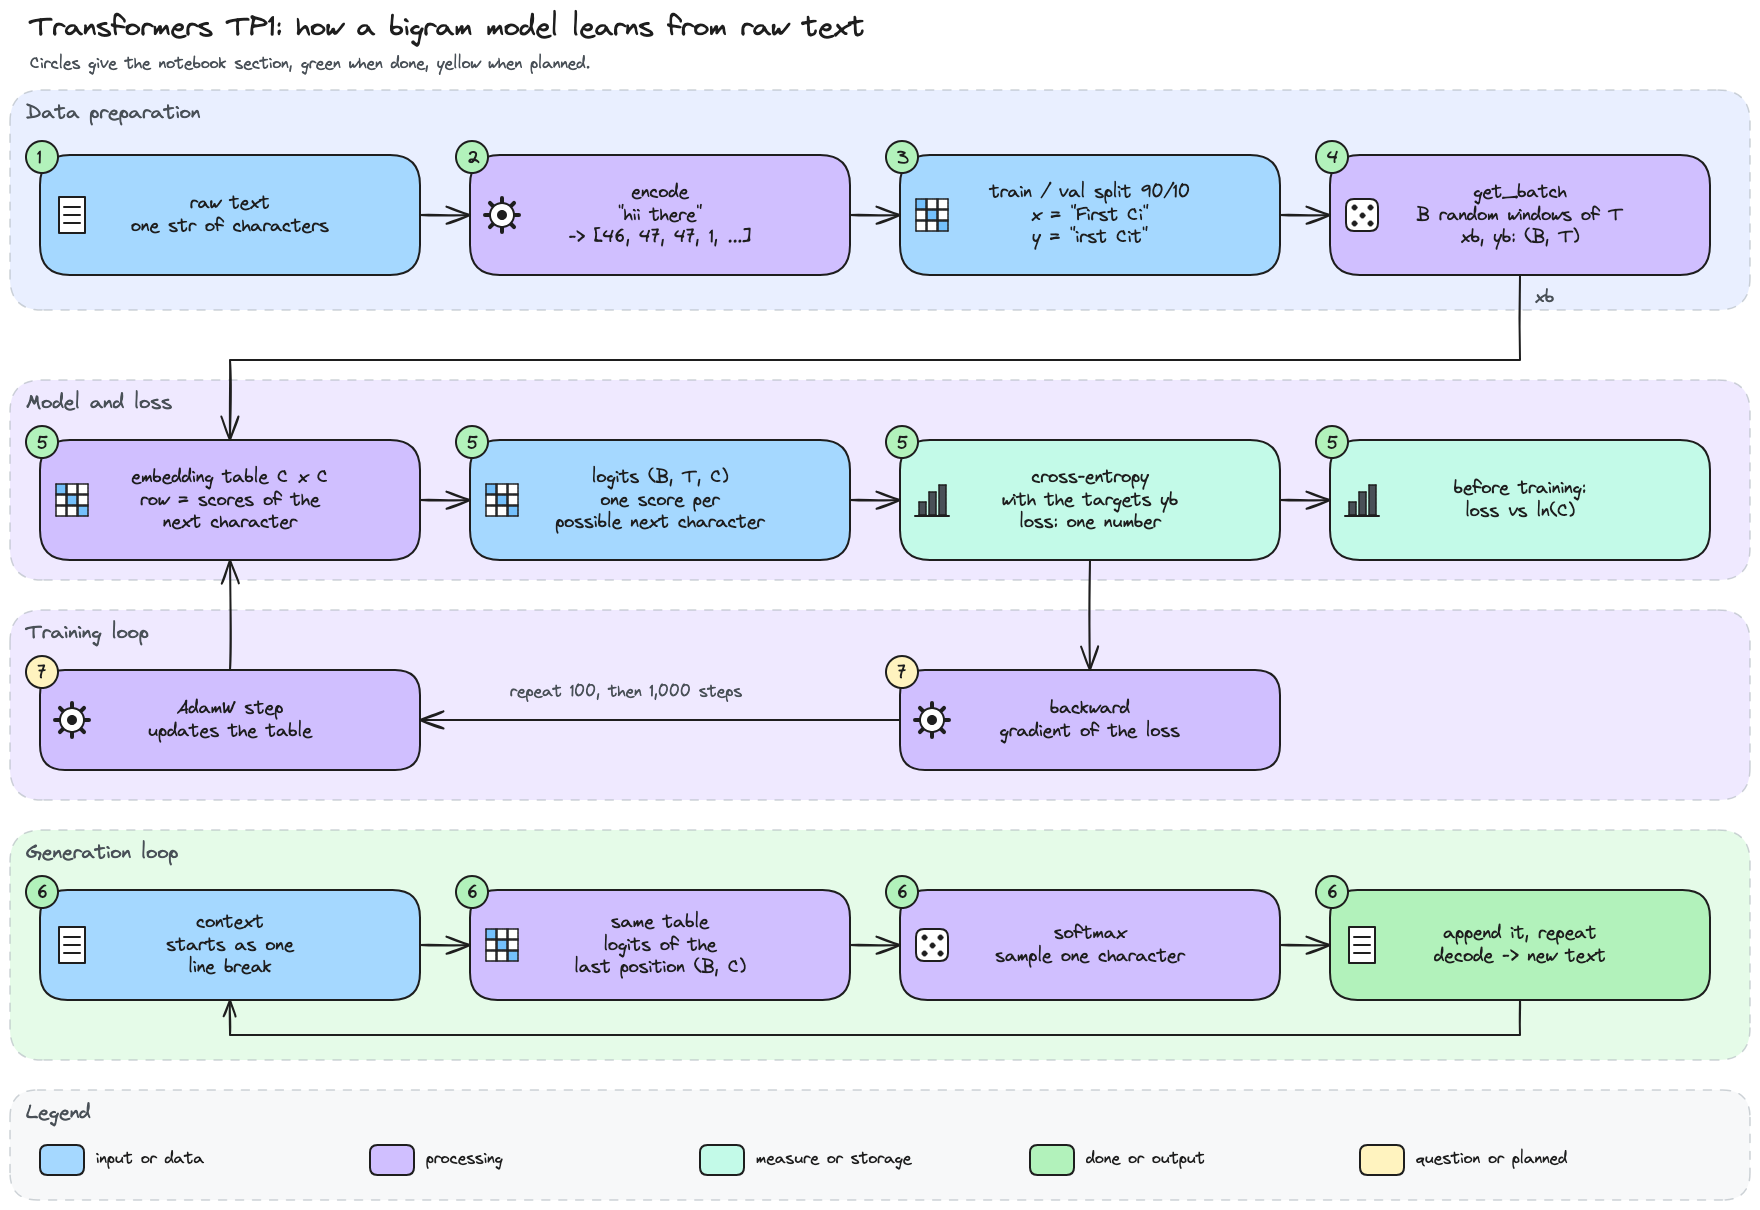

In [1]:
# Workflow diagram: one example through data, model, loss and both loops (diagrams/transformers/).
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp1_workflow.png', width=900))

## 0. My problem and what I carry over

I want to predict the next character of Tiny Shakespeare from the characters before it. I already worked on this corpus in my NLP TPs, so I start from what I learnt there. The diagram links each lesson to what it changes here.

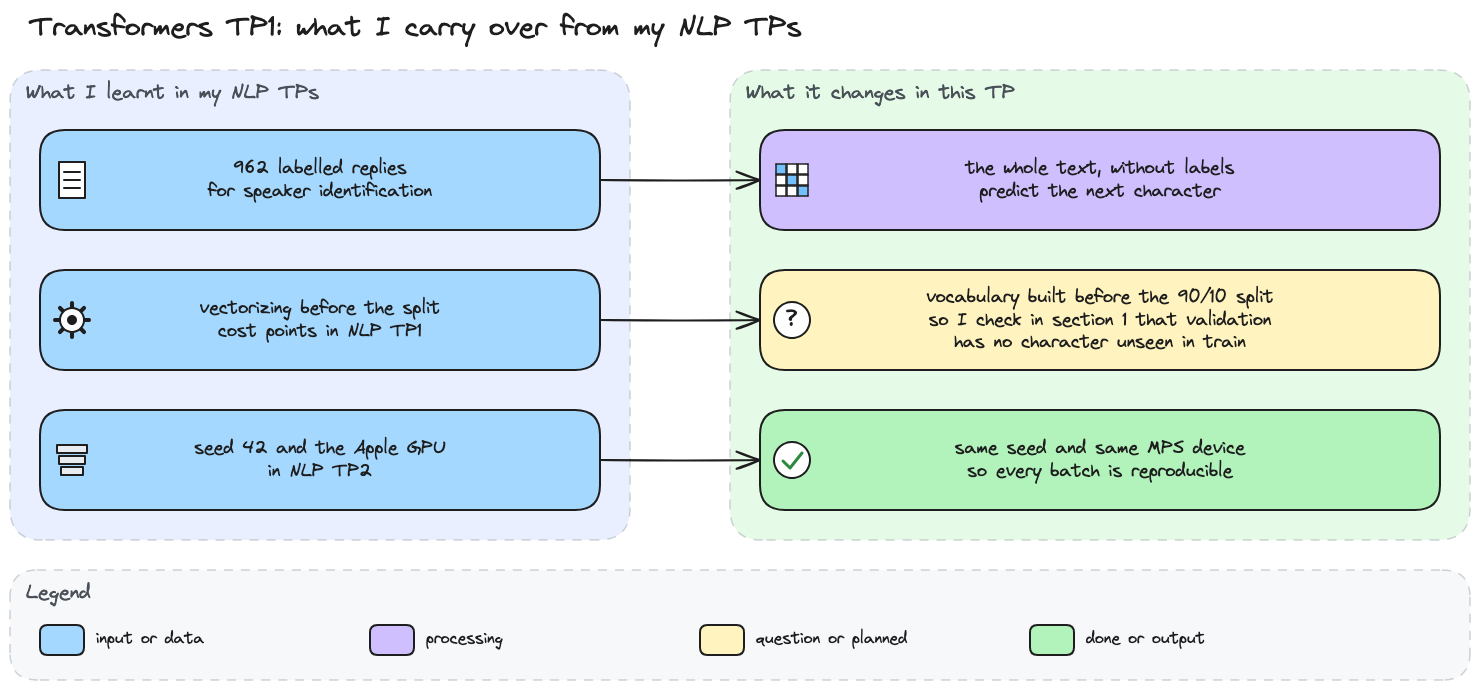

In [2]:
# What I carry over from my NLP TPs (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp1_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - The corpus has fewer than 100 distinct characters, since it is English text with some punctuation. Sections 1 and 2 check it.
> - Before training, the loss is close to ln(C), where C is the number of distinct characters, because random weights give an almost uniform distribution. I test it in section 5.
> - With a learning rate of 1e-3 (the scale of each weight update), 100 steps barely lower the loss and 1,000 steps lower it clearly. Section 7 compares both.
> - After training, samples keep the line breaks and the capitalised speaker names but contain few real words, because the model only sees the previous character. Section 7 tests this too.

### My environment

I use the project's `.venv/bin/python` as kernel and install the dependencies from the terminal.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I use PyTorch because I want to write the forward pass, the loss and the weight update myself. I train on the Apple GPU through MPS (the PyTorch backend for Mac GPUs), and every version is pinned in `requirements.txt`. I fix seed 42 for the random generators, so my batches and samples are the same at every run.

In [3]:
# Environment: versions, hardware, PyTorch device and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, so every random draw below is reproducible.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Apple GPU through MPS when available, CPU otherwise
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'numpy', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Device: {device}, seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
numpy: 2.5.3
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Device: mps, seed: 42


## 1. Download and inspect the corpus

Before I write any model, I want to see the text exactly as the model will read it. What I find here decides the vocabulary of section 2 and what the model will have to generate. The diagram shows the measures I take and the questions they answer.

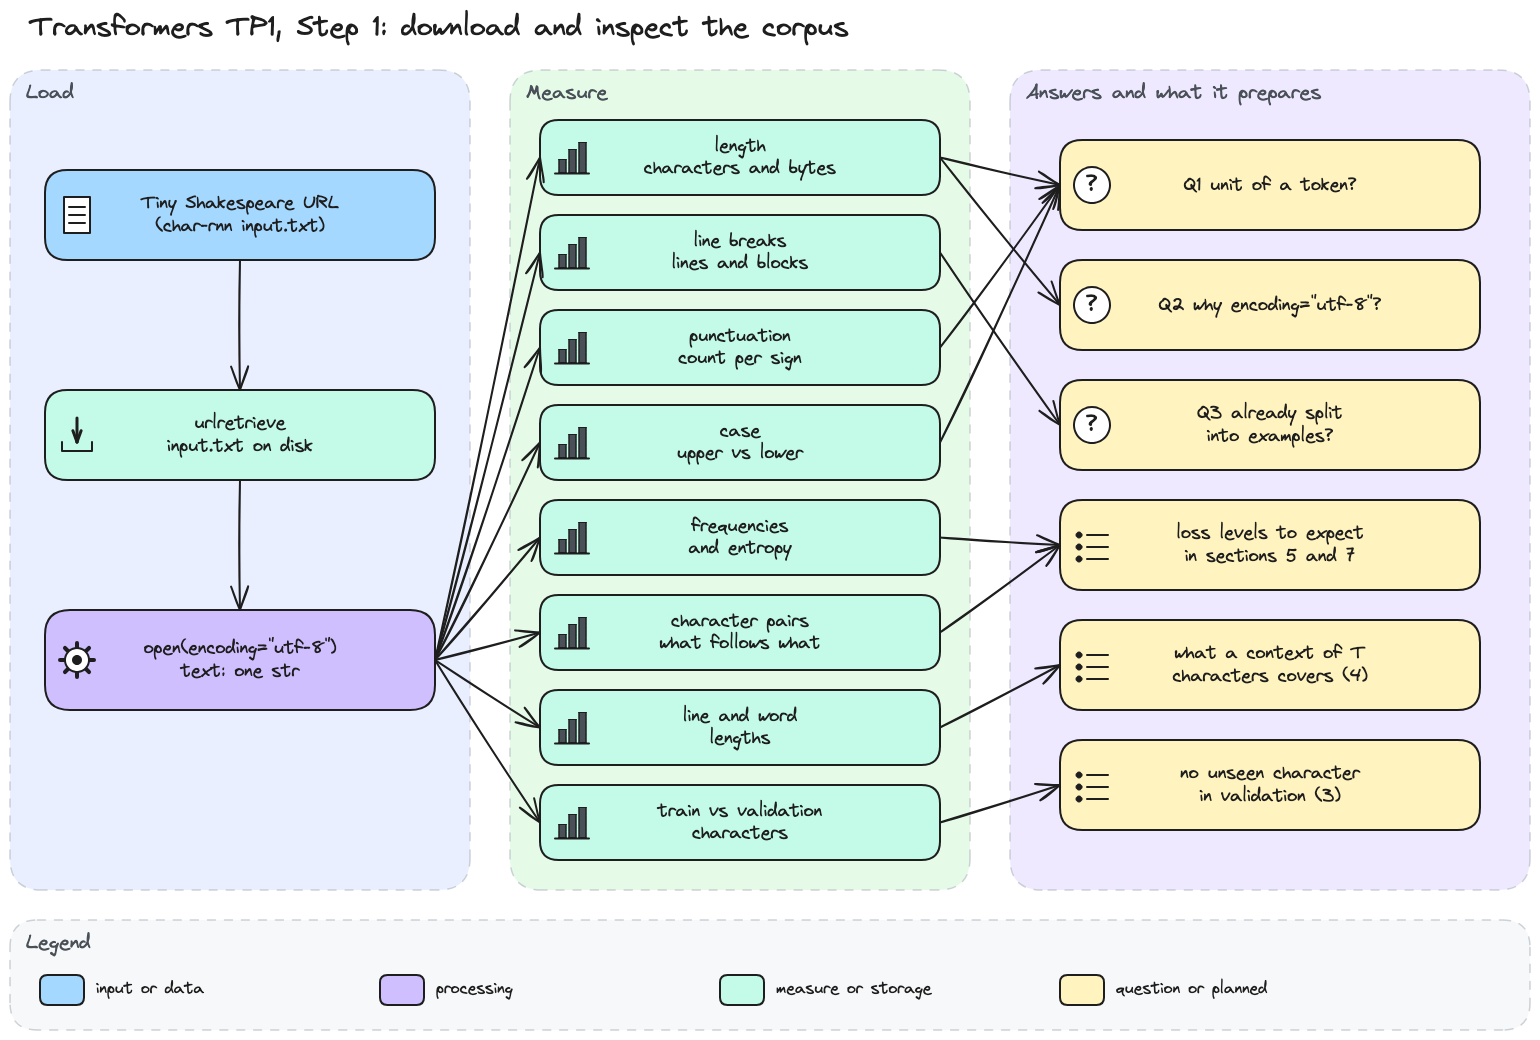

In [4]:
# Step 1 diagram: from the URL to the measures that answer my three questions.
display(Image(filename='diagrams/transformers/tp1_step1.png', width=900))

I download the file once and read it into one string called `text`, because the next TPs reuse this name.

In [5]:
# Download Tiny Shakespeare and read it as one string.
from urllib.request import urlretrieve
import os

url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
urlretrieve(url, "input.txt")
print(os.path.abspath("input.txt"))

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(len(text))

/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/input.txt
1115394


The whole corpus is one Python string of 1,115,394 characters. Nothing is cut into sentences or examples yet, so everything the model learns will come from this single sequence. I print its beginning to see how it is organised.

In [6]:
# The first 1,000 characters, exactly as the model will read them.
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



The text is a play script. A speaker name sits alone on a line and ends with a colon, the reply follows on the next lines, and an empty line closes the block. Punctuation and capitals stay as written, as in `Resolved. resolved.` or `We know't, we know't.`, so the model will have to produce them too.

I opened the file with `encoding="utf-8"`, and I want to know whether this choice changes anything for this file.

In [7]:
# Does the encoding matter here? Compare characters with bytes and look for non-ASCII characters.
import locale

print(f'Characters: {len(text):,}, bytes on disk: {os.path.getsize("input.txt"):,}')
print(f'Non-ASCII characters: {sum(not char.isascii() for char in text)}')
print(f'Default encoding of open() on this machine: {locale.getpreferredencoding(False)}')

Characters: 1,115,394, bytes on disk: 1,115,394
Non-ASCII characters: 0
Default encoding of open() on this machine: UTF-8


The file has as many bytes as characters and no non-ASCII character, so it is plain ASCII and any common encoding decodes it the same way. Why name UTF-8 then? Without it, `open` falls back on the default encoding of the machine. That default is UTF-8 on mine, but naming it makes the notebook read the file the same way on any machine.

The empty lines I saw suggest blocks. I check whether the file is already split into examples.

In [8]:
# Is the text already cut into examples? Count lines, blocks and blocks opened by a speaker name.
import re

line_breaks = text.count('\n')
blocks = text.split('\n\n')
first_lines = [block.split('\n', 1)[0] for block in blocks]
headers = [line for line in first_lines if re.fullmatch(r"[A-Z][A-Za-z' ]*:", line)]  # "Name:"

print(f'Line breaks: {line_breaks:,}')
print(f'Blocks separated by an empty line: {len(blocks):,}')
print(f'Blocks opened by a speaker name alone on its line: {len(headers):,}')

Line breaks: 40,000
Blocks separated by an empty line: 7,222
Blocks opened by a speaker name alone on its line: 7,217


The 40,000 line breaks form the lines, and empty lines cut the text into 7,222 blocks. 7,217 of them open with a speaker name, so the file is laid out for a human reader as a script. Is it split into examples? No. A block has no input and no target, and the model does not see blocks at all. I will build the examples myself in section 3, where each position gives a context and the next character becomes its target.

Next I want to know what the model will have to predict. I group the characters into categories, because each distinct character will become one token.

In [9]:
# Tools: a percentage helper, character category and display, and a bar chart with values.
import string

import matplotlib.pyplot as plt


def percentage(part: int, total: int) -> float:
    """Share of part in total, in percent, rounded to two decimals."""
    return round(100 * part / total, 2)


def character_category(char: str) -> str:
    """Category of one character: line break, space, letter case, digit or punctuation."""
    if char == '\n':
        return 'line break'
    if char == ' ':
        return 'space'
    if char.islower():
        return 'lowercase letter'
    if char.isupper():
        return 'uppercase letter'
    if char.isdigit():
        return 'digit'
    return 'punctuation' if char in string.punctuation else 'other'


def shown(char: str) -> str:
    """Printable form of a character: the line break as \\n and the space as ␣."""
    return {'\n': '\\n', ' ': '␣'}.get(char, char)


def tick(char: str) -> str:
    """Label of a character on a chart, with "$" escaped so it is not read as a formula."""
    return shown(char).replace('$', r'\$')


def bar_chart(labels: list[str], values: list[int], notes: list[str], title: str) -> None:
    """Horizontal bar chart with a note written at the end of each bar."""
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(labels) + 1))
    bars = ax.barh(labels, values, color='#74c0fc')
    ax.bar_label(bars, labels=notes, padding=4)
    ax.set_xlim(0, max(values) * 1.7)
    ax.xaxis.set_major_formatter('{x:,.0f}')
    ax.set_xlabel('occurrences in the text')
    ax.set_title(title)
    ax.spines[['top', 'right']].set_visible(False)
    plt.show()

Distinct characters: 65


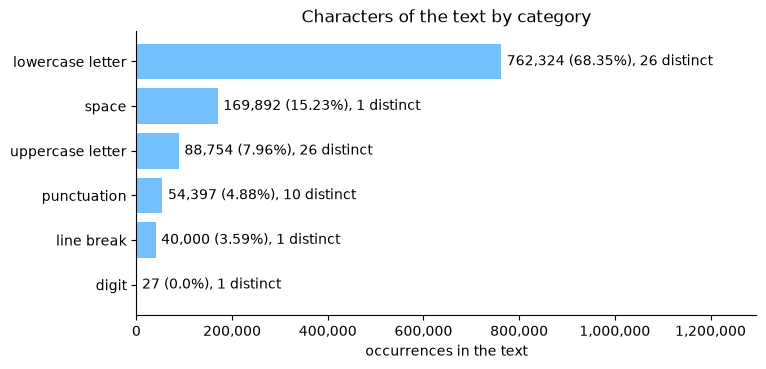

In [10]:
# What kind of characters will the model have to predict?
from collections import Counter

counts = Counter(text)
occurrences, distinct = Counter(), Counter()
for char, n in counts.items():
    occurrences[character_category(char)] += n
    distinct[character_category(char)] += 1

print(f'Distinct characters: {len(counts)}')
categories = sorted(occurrences, key=occurrences.get)
bar_chart(categories, [occurrences[c] for c in categories],
          [f'{occurrences[c]:,} ({percentage(occurrences[c], len(text))}%), '
           f'{distinct[c]} distinct' for c in categories],
          'Characters of the text by category')

What is a token here? One character. The text uses 65 distinct characters, so my vocabulary will have 65 tokens, and my hypothesis of fewer than 100 distinct characters holds for now. Lowercase letters make 68.35% of the text and spaces 15.23%, so most predictions will be a letter or a space. The 26 letters appear in both cases, which means each letter takes two tokens.

Punctuation is only 4.88% of the text, but it has 10 different signs. I look at them one by one.

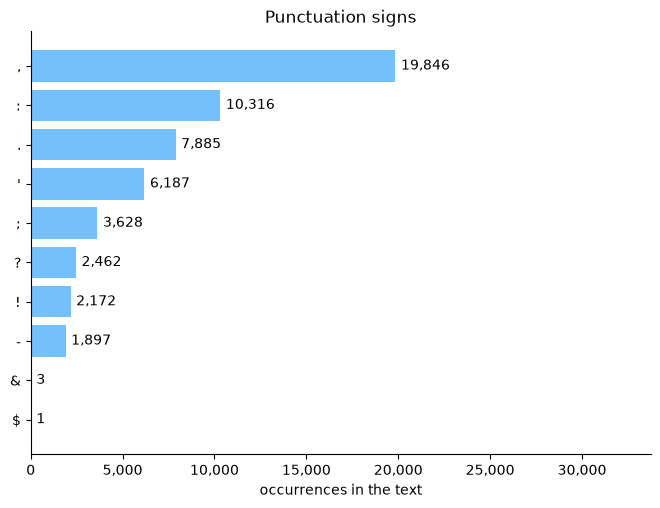

In [11]:
# Which punctuation signs appear, and how often?
signs = sorted((c for c in counts if character_category(c) == 'punctuation'), key=counts.get)
bar_chart([tick(sign) for sign in signs], [counts[sign] for sign in signs],
          [f'{counts[sign]:,}' for sign in signs], 'Punctuation signs')

The comma leads with 19,846 occurrences. The colon comes second with 10,316, and 7,217 of them close a speaker name, so the colon is mostly layout. `&` appears 3 times and `$` once, so the model will almost never see them during training.

The speaker names also seemed to use many capitals. I check how many capitals come from them.

In [12]:
# Where do the capitals come from? Count the capitals that belong to speaker names.
capitals = sum(char.isupper() for char in text)
capitals_in_names = sum(char.isupper() for header in headers for char in header)

print(f'Capitals: {capitals:,}, in speaker names: {capitals_in_names:,} '
      f'({percentage(capitals_in_names, capitals)}%)')
print(f'Speaker names: {len(headers):,}')

Capitals: 88,754, in speaker names: 54,795 (61.74%)
Speaker names: 7,217


61.74% of the capitals are in speaker names. With 54,795 capitals over 7,217 names, a name has about 7.6 capitals, so most names are written in full capitals, unlike `First Citizen` at the top of the file. Case therefore carries part of the script layout, and a good model should learn to write names in capitals after an empty line.

So far I counted characters by kind. A model that ignores the context can only learn how often each character appears, so I look at these frequencies and at what a guess based on them costs.

Uniform guess, ln(65): 4.17 nats
Guess by frequency, entropy of the shares: 3.31 nats


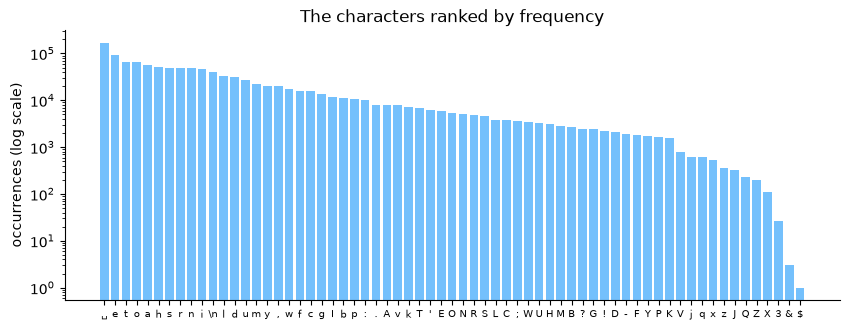

In [13]:
# How often does each character appear, and what does a guess without context cost?
import math

ranked = counts.most_common()
shares = [n / len(text) for _, n in ranked]
entropy = -sum(p * math.log(p) for p in shares)
print(f'Uniform guess, ln({len(counts)}): {math.log(len(counts)):.2f} nats')
print(f'Guess by frequency, entropy of the shares: {entropy:.2f} nats')

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(ranked)), [n for _, n in ranked], color='#74c0fc')
ax.set_yscale('log')
ax.set_xticks(range(len(ranked)), [tick(char) for char, _ in ranked], fontsize=7)
ax.set_ylabel('occurrences (log scale)')
ax.set_title('The characters ranked by frequency')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The chart falls from the space, the most frequent character, down to `$`, seen once. The tail holds rare letters and signs such as `q`, `Z`, `&` and `$`, so the model will get very few examples of them.

Loss is counted in nats, the natural-log unit that PyTorch's cross-entropy uses. A uniform guess over the 65 characters costs 4.17 nats per character. A guess that only uses these frequencies costs 3.31 nats, so a model that learns nothing about context should still get down to about 3.31. I expect a loss near 4.17 before training, because random weights are close to a uniform guess.

A bigram model also sees the previous character. I count which character follows which, to see what this extra information is worth.

In [14]:
# Which character follows which? Count every pair of neighbours, then normalise each row.
import numpy as np

alphabet = sorted(counts)
index = {char: i for i, char in enumerate(alphabet)}
pair_counts = np.zeros((len(alphabet), len(alphabet)))
for (current, following), n in Counter(zip(text, text[1:])).items():
    pair_counts[index[current], index[following]] = n
next_probs = pair_counts / pair_counts.sum(axis=1, keepdims=True)

# Best loss of a bigram table: the mean of -ln P(next | current) over every pair of the text
seen = pair_counts > 0
bigram_loss = -(pair_counts[seen] * np.log(next_probs[seen])).sum() / pair_counts.sum()
print(f'Pairs that occur: {seen.sum():,} of {len(alphabet) ** 2:,}')
print(f'Best loss of a bigram table on this text: {bigram_loss:.2f} nats')
for char in ('\n', ':', 'q'):
    row = next_probs[index[char]]
    top = [j for j in np.argsort(row)[::-1][:3] if row[j] > 0]
    followers = ', '.join(f'"{shown(alphabet[j])}" {100 * row[j]:.1f}%' for j in top)
    print(f'After "{shown(char)}": {followers}')

Pairs that occur: 1,403 of 4,225
Best loss of a bigram table on this text: 2.45 nats
After "\n": "\n" 18.1%, "T" 10.4%, "A" 9.6%
After ":": "\n" 84.9%, "␣" 14.7%, "'" 0.2%
After "q": "u" 100.0%


Only 1,403 of the 4,225 possible pairs ever occur, so about two thirds of my future table will describe pairs the text never shows. Some rows are almost certain. After `q` comes `u` every time, and after `:` comes a line break 84.9% of the time, which confirms that the colon mostly ends a speaker name. After a line break, the most likely next character is another line break (18.1%), then `T` and `A`, capitals that start a name or a verse line.

A table that knew these probabilities exactly would reach a loss of 2.45 nats on this text. Since my bigram model only ever sees one previous character, this is about the best it can reach in section 7. I draw the whole table to see its structure.

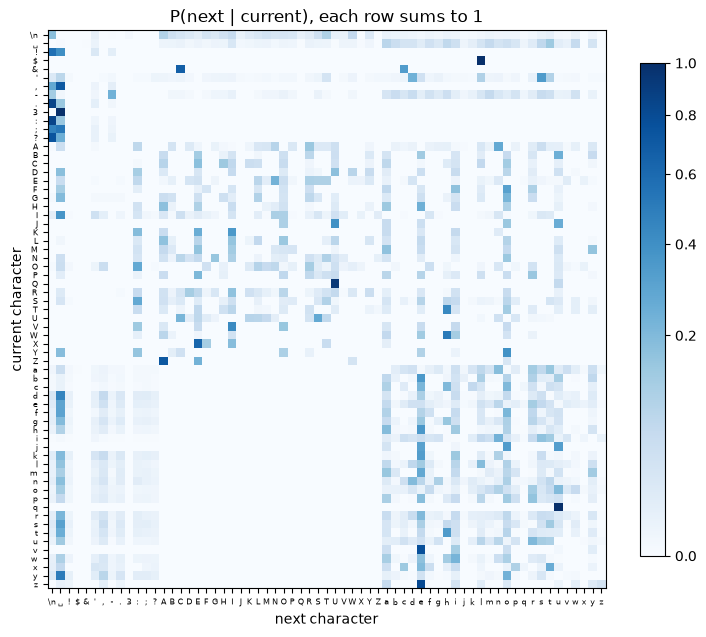

In [15]:
# The same table as a picture: one row per current character, one column per next character.
from matplotlib.colors import PowerNorm

labels = [tick(char) for char in alphabet]
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(next_probs, cmap='Blues', norm=PowerNorm(0.5))  # square root shows faint cells
ax.set_xticks(range(len(alphabet)), labels, fontsize=6)
ax.set_yticks(range(len(alphabet)), labels, fontsize=6)
ax.set_xlabel('next character')
ax.set_ylabel('current character')
ax.set_title('P(next | current), each row sums to 1')
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

The picture has clear blocks. Lowercase letters, at the bottom, are mostly followed by lowercase letters, a space or punctuation, and this bottom right block is the densest. Capitals are followed by lowercase letters inside a word, or by other capitals inside a name written in full capitals. The line break row points to capitals and to the line break itself. Most of the table stays white, which matches the 1,403 pairs seen out of 4,225.

The table tells me what follows one character. I now look at how far a longer context reaches, since the next TPs use T characters of context.

Lines: 32,777, median 39 characters, longest 63
Words: 204,062, median 4 characters


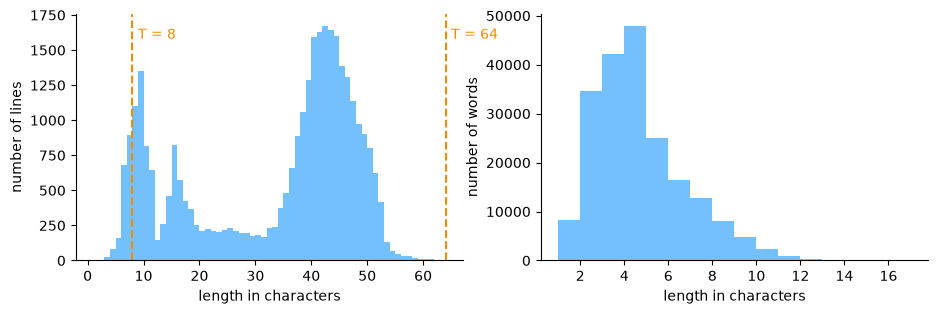

In [16]:
# How long are lines and words? This tells me what a context of T characters can see.
import statistics

line_lengths = [len(line) for line in text.split('\n') if line]
word_lengths = [len(word) for word in re.findall(r"[A-Za-z']+", text)]  # letters, apostrophes
print(f'Lines: {len(line_lengths):,}, median {statistics.median(line_lengths):g} characters, '
      f'longest {max(line_lengths)}')
print(f'Words: {len(word_lengths):,}, median {statistics.median(word_lengths):g} characters')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, lengths, name in ((axes[0], line_lengths, 'lines'), (axes[1], word_lengths, 'words')):
    ax.hist(lengths, bins=range(1, max(lengths) + 2), color='#74c0fc')
    ax.set_xlabel('length in characters')
    ax.set_ylabel(f'number of {name}')
    ax.spines[['top', 'right']].set_visible(False)
for t in (8, 64):
    axes[0].axvline(t, color='#f08c00', linestyle='--')
    axes[0].text(t + 1, axes[0].get_ylim()[1] * 0.9, f'T = {t}', color='#f08c00')
plt.show()

Line lengths have two peaks. The short peak, around 10 characters, fits the speaker-name lines such as `All:` or `First Citizen:`, and the long peak, around 40 to 45 characters, is the verse. The median line has 39 characters and the longest has 63. Words have a median length of 4 characters.

This gives me a feel for T before section 4. With T = 8 the context covers about two words, less than a verse line. With T = 64 it is longer than any line of the text, so the context always reaches back across a line break. My bigram model only uses the last character anyway, so T will matter more for the attention of TP2 than for this table.

Last, the vocabulary is built on the whole text before the 90/10 split of section 3. I check that the last 10% does not bring characters the first 90% never shows.

Characters only in validation: 0 []
Characters only in train: 4 ['$', '&', '3', 'X']
Largest rises in validation: O x1.82, Z x2.07, P x3.31
Largest drops in validation: Q x0.04, J x0.23, Y x0.38


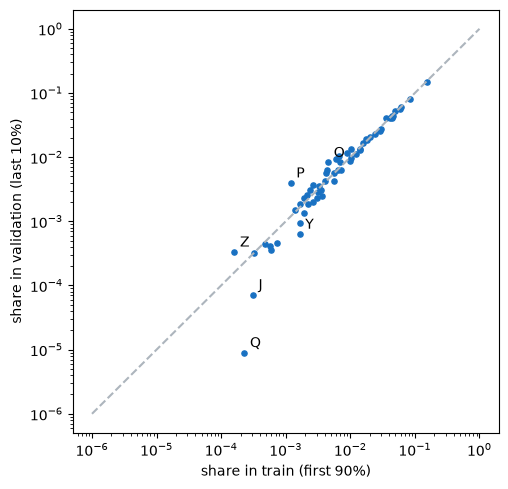

In [17]:
# Does the last 10% of the text, my future validation set, use the same characters as the rest?
split_at = int(0.9 * len(text))
train_counts, val_counts = Counter(text[:split_at]), Counter(text[split_at:])
only_val = sorted(set(val_counts) - set(train_counts))
only_train = [shown(char) for char in sorted(set(train_counts) - set(val_counts))]
print(f'Characters only in validation: {len(only_val)} {only_val}')
print(f'Characters only in train: {len(only_train)} {only_train}')

# Share of each common character in both parts, and the ones whose share moves most
common = [char for char in alphabet if char in val_counts]
train_share = {char: train_counts[char] / split_at for char in common}
val_share = {char: val_counts[char] / (len(text) - split_at) for char in common}
by_ratio = sorted(common, key=lambda char: val_share[char] / train_share[char])
rises = ', '.join(f'{shown(c)} x{val_share[c] / train_share[c]:.2f}' for c in by_ratio[-3:])
drops = ', '.join(f'{shown(c)} x{val_share[c] / train_share[c]:.2f}' for c in by_ratio[:3])
print(f'Largest rises in validation: {rises}')
print(f'Largest drops in validation: {drops}')

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(train_share.values(), val_share.values(), s=14, color='#1971c2')
ax.plot([1e-6, 1], [1e-6, 1], linestyle='--', color='#adb5bd')  # same share in both parts
for char in by_ratio[:3] + by_ratio[-3:]:
    ax.annotate(shown(char), (train_share[char], val_share[char]), xytext=(4, 4),
                textcoords='offset points')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('share in train (first 90%)')
ax.set_ylabel('share in validation (last 10%)')
plt.show()

No character appears only in validation, so building the vocabulary before the split gives validation no unseen token. Four characters, `$`, `&`, `3` and `X`, appear only in train, so the model will never be tested on them.

The points stay close to the diagonal, so both parts use most characters with almost the same shares. The capitals move most. `P` is 3.31 times more frequent in validation and `Z` 2.07 times, while `Q` almost disappears (0.04 times). I suspect the last 10% comes from other scenes with other speaker names. If so, validation is a slightly different text from train, and the validation loss may stay a little above the train loss.

> *My conclusion:*
>
> I keep the text raw, with its case, punctuation and line breaks, because the model has to generate all of them. Section 2 turns the 65 distinct characters into integer ids. I now have three loss levels for sections 5 and 7, 4.17 nats for a uniform guess, 3.31 by frequency alone and 2.45 for a perfect bigram table. I expect my trained table to move from about 4.17 toward 2.45, and never below it. I also expect it to reproduce the script layout, with names in capitals and a line break after the colon.
>
> My answers to the three questions of this step:
>
> 1. A token is one character, and the text has 65 of them.
> 2. Naming UTF-8 makes the decoding independent of the default encoding of the machine, even though this file is plain ASCII.
> 3. The file is not split into examples. It is one string with 7,222 blocks, and section 3 builds the context and target pairs.

## 2. Map characters to integers

PyTorch works on numbers, so each of the 65 characters of section 1 needs an integer id. I build a sorted vocabulary and two maps that must invert each other, then I test them. The diagram shows the way from a string to ids and back, and what I check.

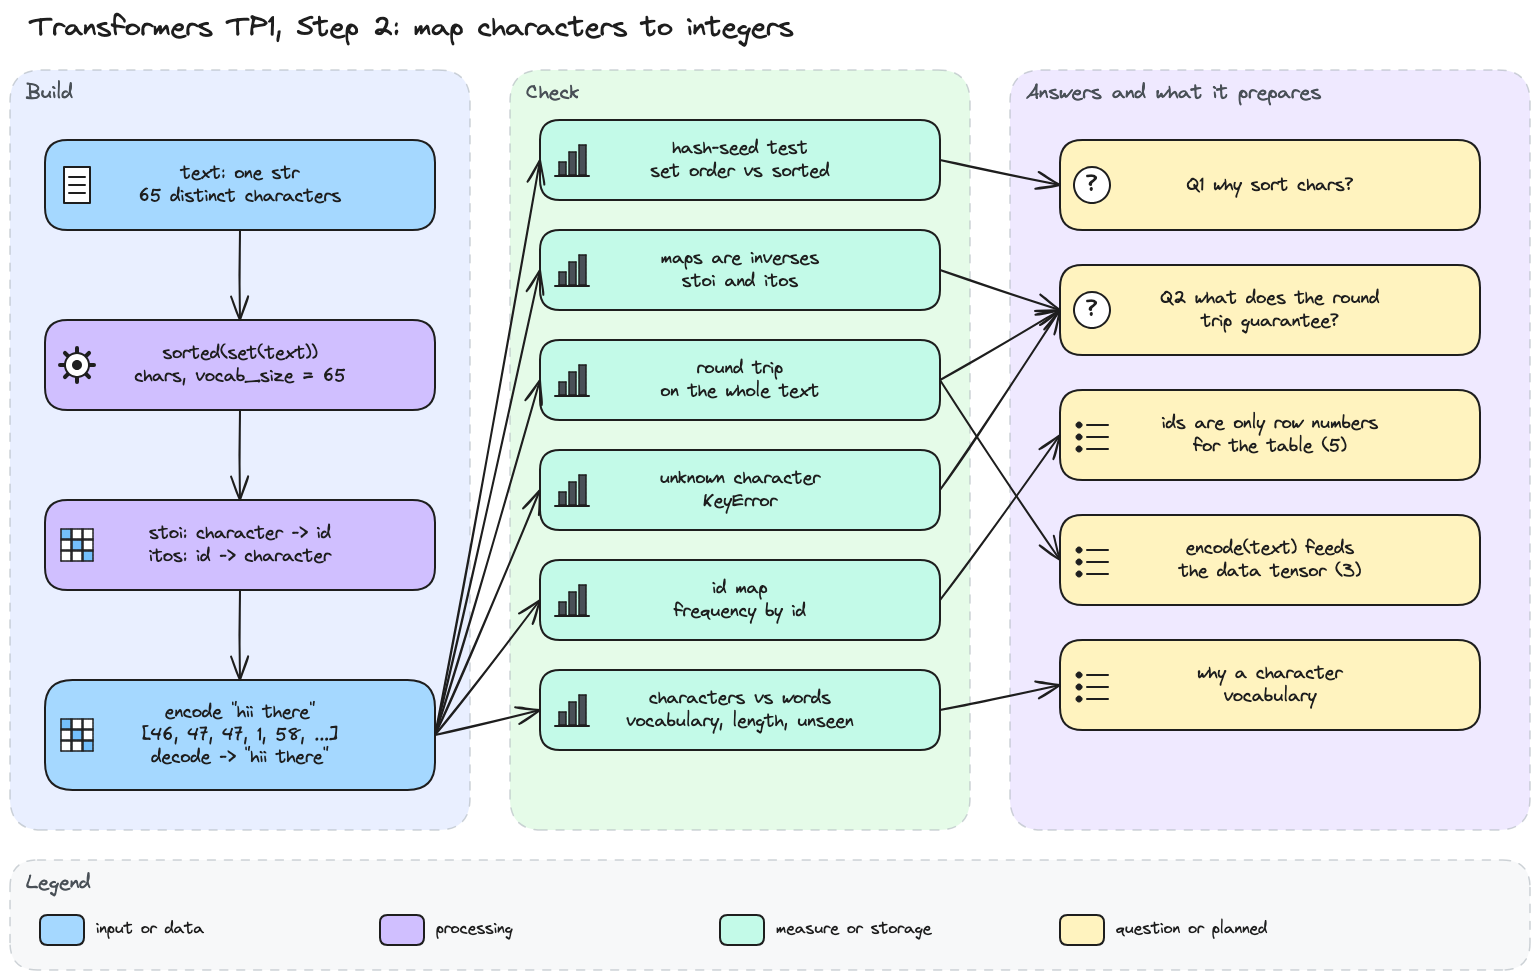

In [18]:
# Step 2 diagram: vocabulary, maps, encode and decode, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step2.png', width=900))

In [19]:
# Vocabulary: the distinct characters of the text, sorted and numbered, then the two maps.
chars = sorted(list(set(text)))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

print(f'vocab_size: {vocab_size}')
print(f'Vocabulary in id order: {"".join(shown(ch) for ch in chars)}')
print(f'itos undoes stoi: {all(itos[stoi[ch]] == ch for ch in chars)}')
print(f'stoi undoes itos: {all(stoi[itos[i]] == i for i in range(vocab_size))}')

vocab_size: 65
Vocabulary in id order: \n␣!$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
itos undoes stoi: True
stoi undoes itos: True


The vocabulary has 65 characters, so my hypothesis of fewer than 100 distinct characters is confirmed. Both checks print True, so every character has exactly one id and every id exactly one character. In id order, the line break comes first, then the space, the signs and the digit, the capitals and the lowercase letters. That is the order of the character codes, because `sorted` compares characters by their code.

A set has no order of its own, though. I want to see what would happen if I numbered the characters straight from the set.

In [20]:
# Why sort? Build the vocabulary in three new Python processes, each with another hash seed.
import os
import subprocess
import sys

SNIPPET = ("text = open('input.txt', encoding='utf-8').read()\n"
           "print('set', repr(''.join(list(set(text)))[:12]),"
           " ' sorted', repr(''.join(sorted(set(text)))[:12]))")

for seed in ('1', '2', '3'):
    child = subprocess.run([sys.executable, '-c', SNIPPET], capture_output=True, text=True,
                           env={**os.environ, 'PYTHONHASHSEED': seed})
    print(f'hash seed {seed}: {child.stdout.strip()}')

hash seed 1: set 'VtM.;k3b$LyR'  sorted "\n !$&',-.3:;"
hash seed 2: set 'hkIJEmO:VG&p'  sorted "\n !$&',-.3:;"
hash seed 3: set 'JayQo:fDk?u!'  sorted "\n !$&',-.3:;"


In each new process the set gives the characters in another order, while the sorted list starts with the same characters every time. Python shuffles the order of a set of strings with a hash seed that changes at each start. Why sort `chars` then? Without sorting, `h` could get id 46 in one run and another id in the next. The rows of the table I train in section 5 would then point to other characters when I reload it, and generated ids would decode into the wrong text.

With a stable numbering, I can now write `encode` and `decode`.

In [21]:
# Encode and decode as two lambdas, tried on a short message.
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join([itos[i] for i in ids])

message = "hii there"
print(encode(message))
print(decode(encode(message)))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


`hii there` becomes nine ids, one per character. The two `i` both get 47 and the two `h` both get 46, so a character always keeps its id, and the space is 1. Decoding gives the message back.

I check whether this still holds on the whole text, and what happens with a character the text never uses.

In [22]:
# Does the round trip hold on the whole text? And what happens with a character outside it?
print(f'decode(encode(text)) == text: {decode(encode(text)) == text}')
print(f'Ids produced for the whole text: {len(encode(text)):,}')

try:
    encode("café")
except KeyError as error:
    print(f'encode("café") raises KeyError: {error}')

decode(encode(text)) == text: True
Ids produced for the whole text: 1,115,394
encode("café") raises KeyError: 'é'


The round trip gives back the whole text exactly, from 1,115,394 ids. What does the test guarantee? That encoding loses nothing on this vocabulary, since each character has one id and each id one character. So any ids the model produces can always be turned back into text. It says nothing about new characters, since `é` raises a KeyError. My vocabulary is closed, which is safe here because section 1 showed that validation has no character missing from train.

The ids look like numbers, so I want to check whether they carry any meaning.

line break: ids 0 to 0
space: ids 1 to 1
punctuation: ids 2 to 12
digit: ids 9 to 9
uppercase letter: ids 13 to 38
lowercase letter: ids 39 to 64
'A' -> 13, 'a' -> 39


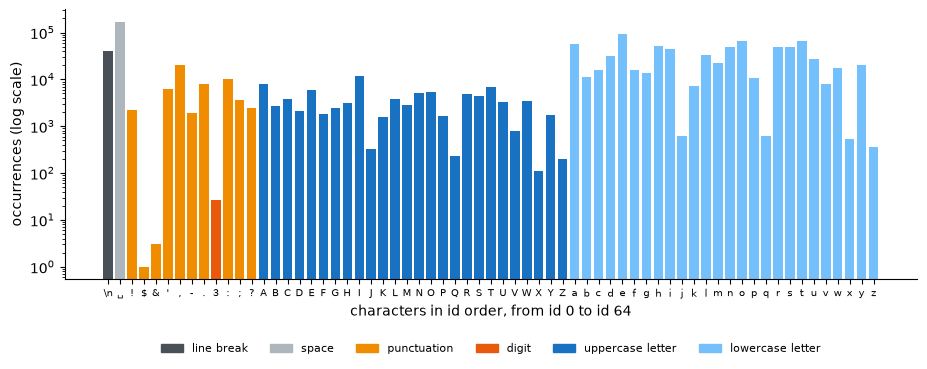

In [23]:
# What does an id say? Frequency of each id, in id order, coloured by the category of its character.
from matplotlib.patches import Patch

CATEGORY_COLOURS = {'line break': '#495057', 'space': '#adb5bd', 'punctuation': '#f08c00',
                    'digit': '#e8590c', 'uppercase letter': '#1971c2',
                    'lowercase letter': '#74c0fc'}

for category in CATEGORY_COLOURS:
    ids = [stoi[ch] for ch in chars if character_category(ch) == category]
    print(f'{category}: ids {min(ids)} to {max(ids)}')
print(f"'A' -> {stoi['A']}, 'a' -> {stoi['a']}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(range(vocab_size), [counts[ch] for ch in chars],
       color=[CATEGORY_COLOURS[character_category(ch)] for ch in chars])
ax.set_yscale('log')
ax.set_xticks(range(vocab_size), [tick(ch) for ch in chars], fontsize=7)
ax.set_xlabel('characters in id order, from id 0 to id 64')
ax.set_ylabel('occurrences (log scale)')
legend = [Patch(color=colour, label=name) for name, colour in CATEGORY_COLOURS.items()]
ax.legend(handles=legend, fontsize=8, ncols=6, frameon=False, loc='upper center',
          bbox_to_anchor=(0.5, -0.2))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Ids follow the character codes. The line break is 0, the space 1, the signs and the digit 2 to 12, the capitals 13 to 38 and the lowercase letters 39 to 64. Along the ids, the frequency jumps up and down, and `A` (13) sits far from `a` (39) although they are the same letter. So an id says nothing about how frequent a character is or how close two characters are. It only numbers a row, and the table of section 5 will have to learn what each row means.

I chose one token per character. I compare it with one token per word, the unit I used in my NLP TPs.

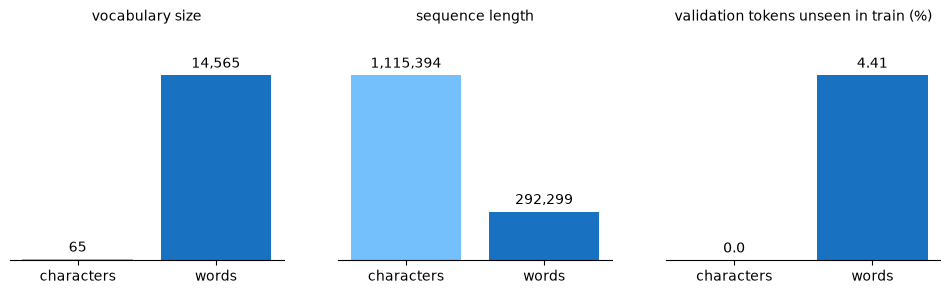

In [24]:
# Characters or words? Compare vocabulary size, sequence length and unseen tokens in validation.
WORD_PATTERN = r"[A-Za-z']+|[^A-Za-z'\s]|\n"  # a word, a single sign or a line break

tokenizers = {'characters': list, 'words': lambda s: re.findall(WORD_PATTERN, s)}
measures = {}
for name, tokenize in tokenizers.items():
    train_tokens, val_tokens = tokenize(text[:split_at]), tokenize(text[split_at:])
    known = set(train_tokens)
    unseen = sum(token not in known for token in val_tokens)
    measures[name] = [len(known | set(val_tokens)), len(train_tokens) + len(val_tokens),
                      percentage(unseen, len(val_tokens))]

titles = ['vocabulary size', 'sequence length', 'validation tokens unseen in train (%)']
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for k, (ax, title) in enumerate(zip(axes, titles)):
    values = [measures[name][k] for name in tokenizers]
    bars = ax.bar(list(tokenizers), values, color=['#74c0fc', '#1971c2'])
    ax.bar_label(bars, labels=[f'{value:,}' for value in values], padding=3)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, max(values) * 1.25)
    ax.set_yticks([])
    ax.spines[['top', 'right', 'left']].set_visible(False)
plt.show()

Characters give a vocabulary of 65 tokens against 14,565 for words, and no validation character is unseen. With words, 4.41% of validation tokens never appear in train, so I would need an unknown token as in NLP TP2, and these words would be lost. The price of characters is length. The text becomes 1,115,394 tokens instead of 292,299, about 3.8 times more, so a context of T tokens covers fewer words. A token can also be a piece of a word, which sits between these two choices.

> *My conclusion:*
>
> I now have a closed vocabulary of 65 characters, numbered in sorted order so that the ids stay the same at every run. `encode` turns the text into 1,115,394 ids without losing anything, and section 3 turns them into a tensor. An id is only a row number, so the table of section 5 has to learn what each row means.
>
> My answers to the two questions of this step:
>
> 1. I sort `chars` because a set has no stable order between runs, and a character must keep the same id so that the trained table and the decoding stay valid.
> 2. The round trip guarantees that encoding loses nothing on this vocabulary, since the two maps invert each other. It guarantees nothing for a character outside the vocabulary, which raises a KeyError.

## 3. Build the expected predictions

A model learns from pairs of a context and the character that follows it. I turn the ids into one tensor, split it into train and validation, and cut one block to see which pairs it holds. The diagram shows the path and the checks behind my answers.

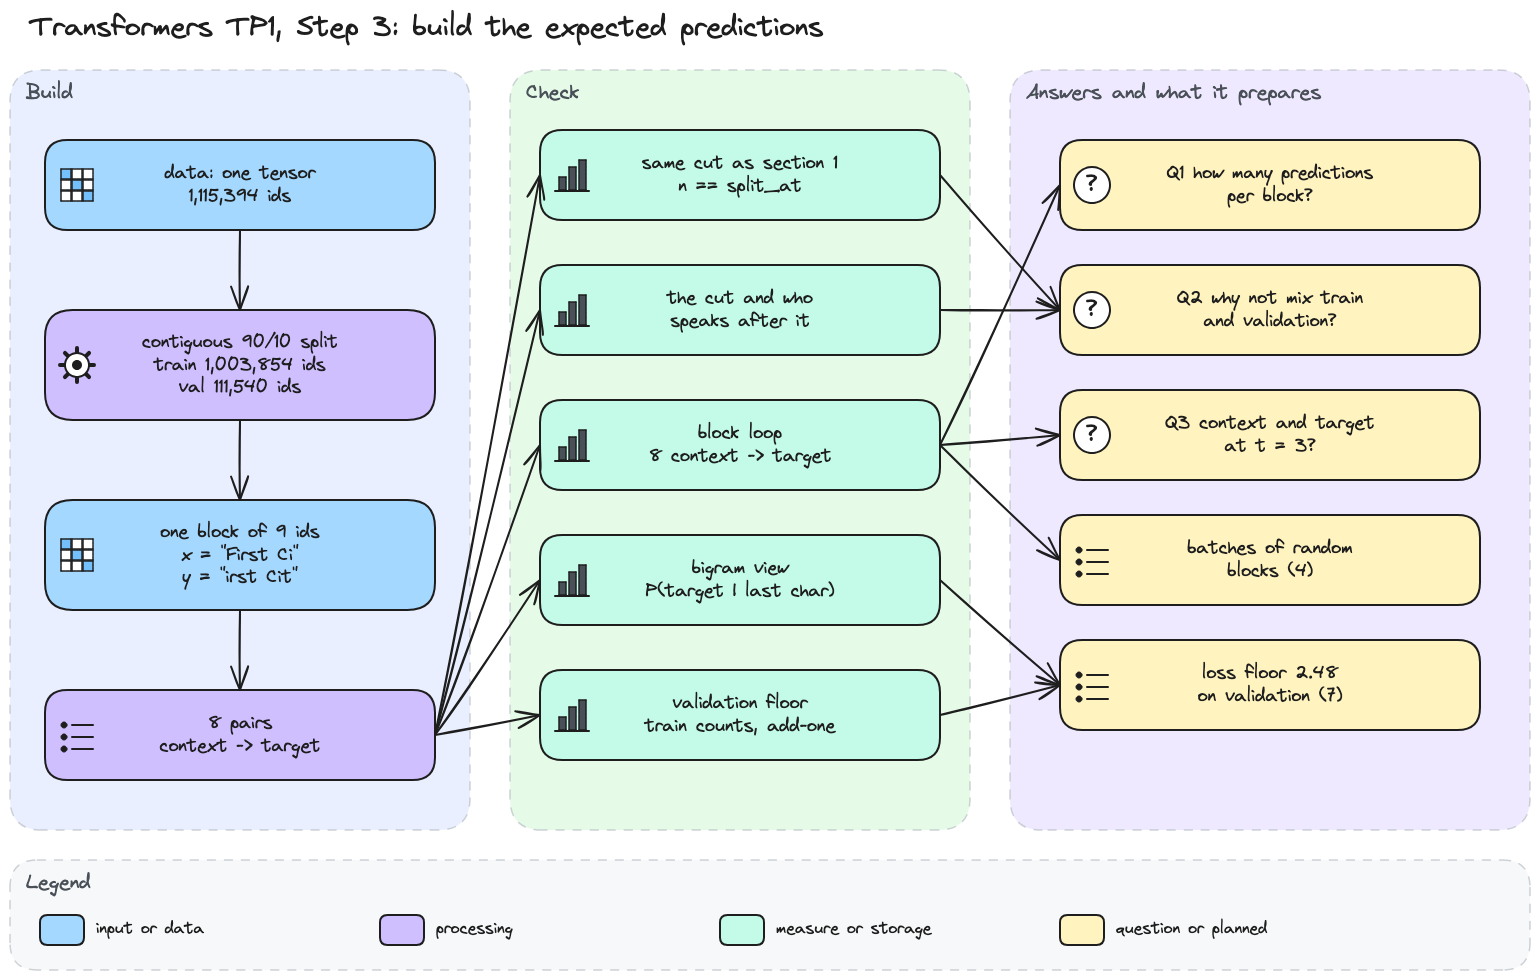

In [25]:
# Step 3 diagram: tensor, split, one block of predictions, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step3.png', width=900))

In [26]:
# The whole text as one tensor of ids, then a 90/10 split by position.
data = torch.tensor(encode(text), dtype=torch.long)

n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

print(f'data: shape {tuple(data.shape)}, dtype {data.dtype}')
print(f'First ids: {data[:9].tolist()} -> {decode(data[:9].tolist())!r}')
print(f'train_data: {len(train_data):,} ids, val_data: {len(val_data):,} ids')
print(f'Same cut as split_at in section 1: {n == split_at}')

data: shape (1115394,), dtype torch.int64
First ids: [18, 47, 56, 57, 58, 1, 15, 47, 58] -> 'First Cit'
train_data: 1,003,854 ids, val_data: 111,540 ids
Same cut as split_at in section 1: True


The text is now one tensor of 1,115,394 ids, one per character, and its first ids decode back to `First Cit`. I keep the 64-bit integer type, because these ids will index the rows of the table in section 5. The cut gives 1,003,854 ids to train and 111,540 to validation, at the same place as `split_at` in section 1. So the check of section 1 still holds, and validation has no character missing from train.

The split takes the first 90% for train and the last 10% for validation, without shuffling. I want to see where this cut falls and what lies after it.

Before the cut: 'ntleman thus grieved as I?\nBut who comes here'
After the cut:  '?\n\nGREMIO:\nGood morrow, neighbour Baptista.\n\n'
Validation speakers: 36, never speaking in train: 24
Validation blocks they open: 367 of 919


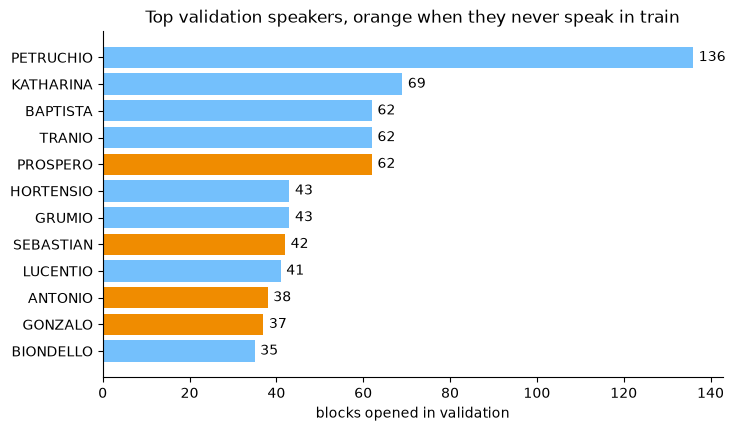

In [27]:
# Where does the cut fall, and who speaks on each side of it?
HEADER = r"(?:\A|\n\n)([A-Z][A-Za-z' ]*):\n"  # a name alone on the first line of a block

print(f'Before the cut: {decode(data[n - 45:n].tolist())!r}')
print(f'After the cut:  {decode(data[n:n + 45].tolist())!r}')

train_names = Counter(re.findall(HEADER, text[:n]))
val_names = Counter(re.findall(HEADER, text[n:]))
new_names = [name for name in val_names if name not in train_names]
print(f'Validation speakers: {len(val_names)}, never speaking in train: {len(new_names)}')
print(f'Validation blocks they open: {sum(val_names[name] for name in new_names)} '
      f'of {sum(val_names.values())}')

top = val_names.most_common(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh([name for name, _ in top], [count for _, count in top],
               color=['#f08c00' if name in new_names else '#74c0fc' for name, _ in top])
ax.bar_label(bars, padding=4)
ax.set_xlabel('blocks opened in validation')
ax.set_title('Top validation speakers, orange when they never speak in train')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The cut even falls inside a sentence, between `But who comes here` and its question mark. After it, validation is partly made of other scenes. 24 of its 36 speakers never speak in train, and they open 367 of its 919 blocks. The chart shows two groups. PETRUCHIO, KATHARINA and BAPTISTA already speak in train, while PROSPERO, SEBASTIAN, ANTONIO and GONZALO only appear in validation. PETRUCHIO alone opens 136 blocks and PROSPERO 62, which explains why `P` was more frequent in validation in section 1.

Why not mix train and validation? A window that starts one character later shares 8 of its 9 characters with the previous one. If I mixed windows at random, validation would hold almost the same text as train, and its loss would reward memory. With a contiguous cut, validation measures how the model does on scenes and speakers it never saw.

Now I cut one block of the train set to see the pairs it holds.

In [28]:
# One block of the train set: x is the input, y the same characters shifted by one position.
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]

for t in range(block_size):
    context = x[:t + 1]
    target = y[t]
    print(context, "->", target, f"   {decode(context.tolist())!r} -> {itos[target.item()]!r}")

tensor([18]) -> tensor(47)    'F' -> 'i'
tensor([18, 47]) -> tensor(56)    'Fi' -> 'r'
tensor([18, 47, 56]) -> tensor(57)    'Fir' -> 's'
tensor([18, 47, 56, 57]) -> tensor(58)    'Firs' -> 't'
tensor([18, 47, 56, 57, 58]) -> tensor(1)    'First' -> ' '
tensor([18, 47, 56, 57, 58,  1]) -> tensor(15)    'First ' -> 'C'
tensor([18, 47, 56, 57, 58,  1, 15]) -> tensor(47)    'First C' -> 'i'
tensor([18, 47, 56, 57, 58,  1, 15, 47]) -> tensor(58)    'First Ci' -> 't'


How many predictions does this block produce? Eight, one per position, from the 9 characters of `train_data[:9]`. Each target becomes the last character of the next context, so the contexts grow from 1 to 8 characters. For t = 3, the context is `tensor([18, 47, 56, 57])`, which is `Firs`, and the target is `tensor(58)`, which is `t`. Sliding over the whole train set, every position gives one prediction, so about 1,003,853 of them (n minus 1).

My bigram model will only look at the last character of each context. I check what that single character says about each target.

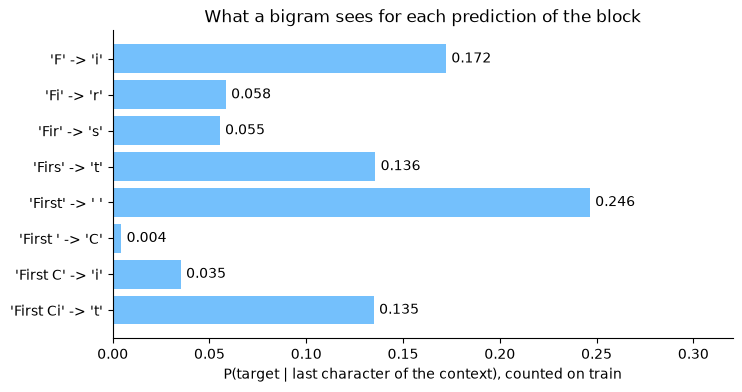

In [29]:
# What does the last character of each context say about its target? Pairs counted on train only.
train_pairs = torch.zeros((vocab_size, vocab_size))
train_pairs.index_put_((train_data[:-1], train_data[1:]), torch.ones(n - 1), accumulate=True)
train_probs = train_pairs / train_pairs.sum(dim=1, keepdim=True)

labels = [f'{decode(x[:t + 1].tolist())!r} -> {itos[y[t].item()]!r}' for t in range(block_size)]
probs = [train_probs[x[t], y[t]].item() for t in range(block_size)]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(labels[::-1], probs[::-1], color='#74c0fc')
ax.bar_label(bars, labels=[f'{p:.3f}' for p in probs[::-1]], padding=4)
ax.set_xlim(0, max(probs) * 1.3)
ax.set_xlabel('P(target | last character of the context), counted on train')
ax.set_title('What a bigram sees for each prediction of the block')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

For a bigram, `First ` followed by `C` is the hardest prediction with 0.004, since many characters can follow a space. `First` followed by a space is the easiest with 0.246. After `C`, the bigram gives `i` only 0.035, although anyone reading `First C` at the top of the play guesses `Citizen`. One character cannot see the word it belongs to. Longer contexts, which the attention of TP2 will use, should fix exactly this kind of prediction.

The next question is how low such a table can go on text it never saw.

In [30]:
# How low can a bigram table go on validation? I score both parts with the train counts.
val_seen = train_pairs[val_data[:-1], val_data[1:]] > 0
unseen = int((~val_seen).sum())
print(f'Validation pairs never seen in train: {unseen} of {len(val_data) - 1:,} '
      f'({percentage(unseen, len(val_data) - 1)}%)')

smoothed = (train_pairs + 1) / (train_pairs + 1).sum(dim=1, keepdim=True)  # add-one smoothing
train_loss = -torch.log(train_probs[train_data[:-1], train_data[1:]]).mean().item()
val_loss = -torch.log(smoothed[val_data[:-1], val_data[1:]]).mean().item()
print(f'Table counted on train, loss on train: {train_loss:.2f} nats')
print(f'Same table with add-one smoothing, loss on validation: {val_loss:.2f} nats')

Validation pairs never seen in train: 187 of 111,539 (0.17%)
Table counted on train, loss on train: 2.45 nats
Same table with add-one smoothing, loss on validation: 2.48 nats


Only 187 of the 111,539 validation pairs never appear in train, 0.17%. Add-one smoothing adds one to every count, so these pairs keep a small probability instead of an infinite loss. The table counted on train reaches 2.45 nats on train and 2.48 on validation. So even with perfect counts, a bigram model should not go below about 2.48 on validation, which is my realistic target for section 7. The gap of 0.03 is small, so the new scenes change which characters follow which only a little.

> *My conclusion:*
>
> The text is one tensor of 1,115,394 ids, cut into 1,003,854 for train and 111,540 for validation. The cut is contiguous, so validation also tests scenes and speakers the model never saw. Every position gives one prediction, and a block of 9 characters gives 8 of them, with contexts from 1 to 8 characters. A bigram only sees the last character, so its loss should not go below 2.45 on train and 2.48 on validation. Section 4 stacks many random blocks into one batch.
>
> My answers to the three questions of this step:
>
> 1. A block of `block_size + 1` = 9 characters produces 8 predictions, one per position.
> 2. Windows one character apart share 8 of their 9 characters, so mixing them would put almost the same text in both sets. The contiguous cut keeps validation on unseen text.
> 3. For t = 3, the context is `[18, 47, 56, 57]` (`Firs`) and the target is 58 (`t`).

## 4. Sample a mini-batch

One block gives 8 predictions, and training block by block would be slow. I stack B random blocks of length T into one batch, so the model computes all their predictions in parallel. The diagram shows how a batch is drawn and what I check.

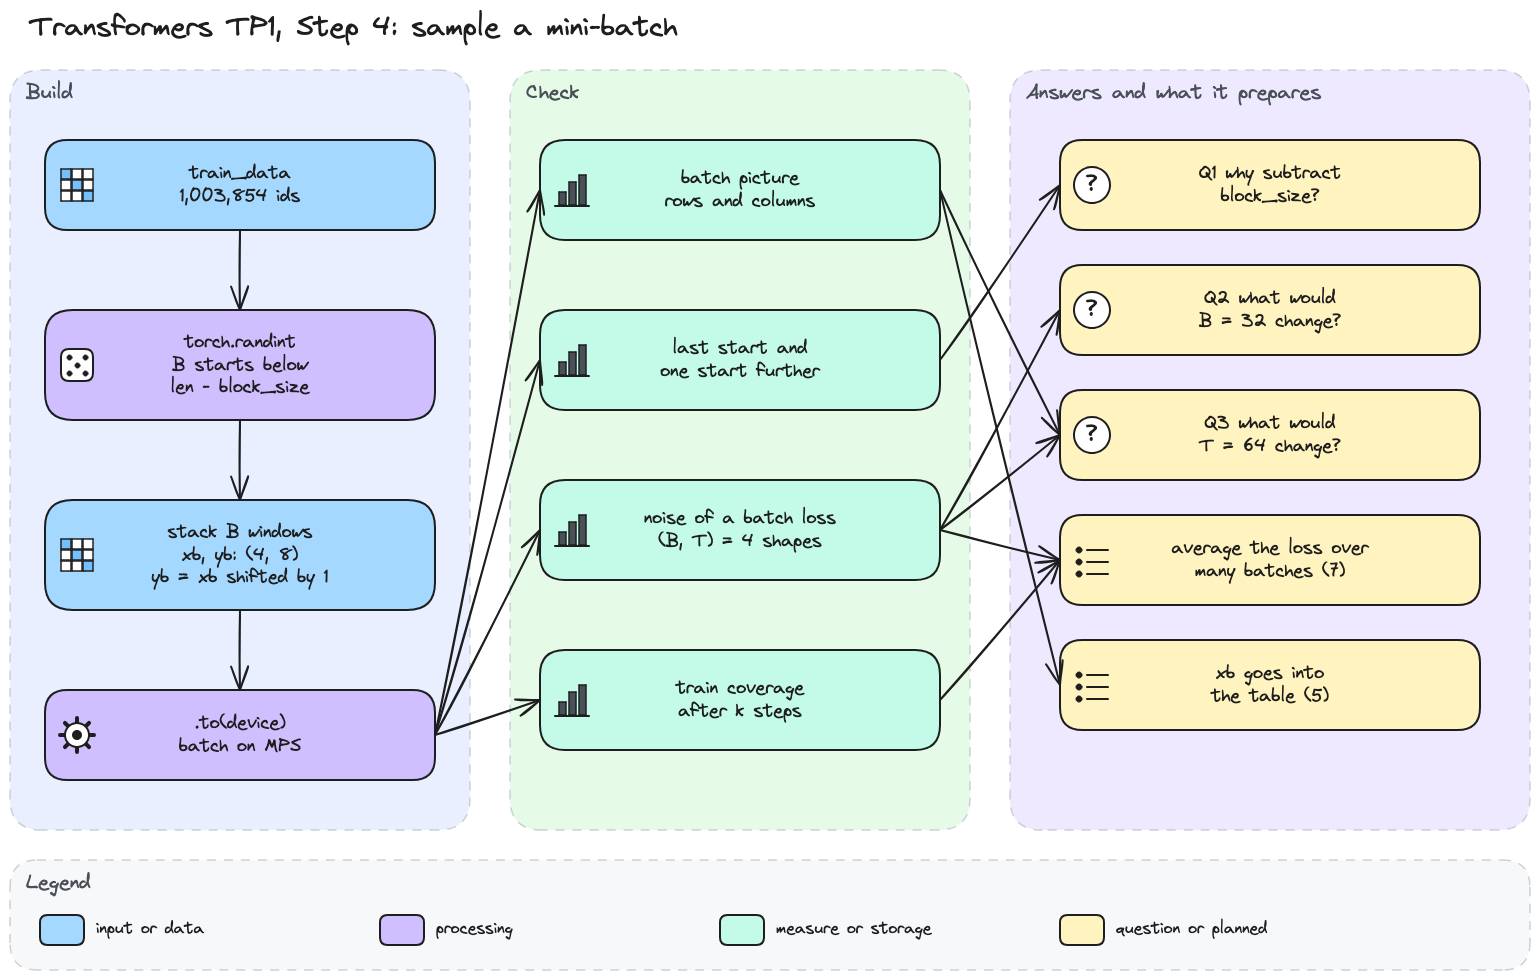

In [31]:
# Step 4 diagram: random starts, stacked windows, the device, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step4.png', width=900))

In [32]:
# Mini-batches: B random blocks of length T from one split, sent to the device.
batch_size = 4
block_size = 8


def get_batch(split: str) -> tuple[torch.Tensor, torch.Tensor]:
    """B random blocks of one split as inputs x and targets y shifted by one position."""
    source = train_data if split == "train" else val_data
    starts = torch.randint(
        len(source) - block_size, (batch_size,)
    )
    x = torch.stack([
        source[i : i + block_size] for i in starts
    ])
    y = torch.stack([
        source[i + 1 : i + block_size + 1] for i in starts
    ])
    return x.to(device), y.to(device)


xb, yb = get_batch("train")
print(xb.shape, yb.shape)
print(f'device: {xb.device}, dtype: {xb.dtype}')

torch.Size([4, 8]) torch.Size([4, 8])
device: mps:0, dtype: torch.int64


Both tensors have shape (4, 8) and sit on the Apple GPU, with the same 64-bit ids as before. So one batch holds 4 × 8 = 32 predictions, against 8 for the single block of section 3. I want to see what the rows and the columns hold.

yb is xb shifted by one position: True
row 0: 's his lo' -> ' his lov'
row 1: ' there c' -> 'there ca'
row 2: 'ENCE:\nTo' -> 'NCE:\nTo '
row 3: 'st, with' -> 't, with\n'


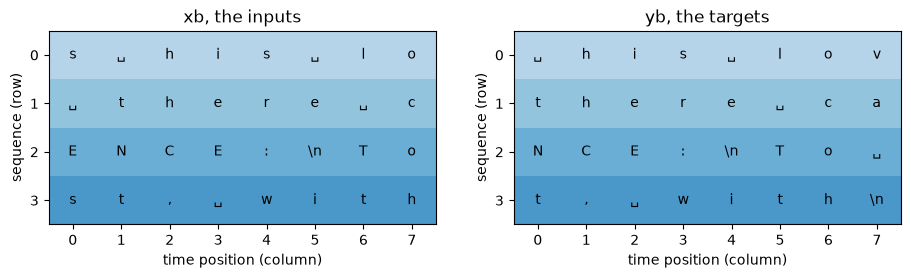

In [33]:
# What is inside a batch? Each row decoded, the shift checked, then xb and yb as character grids.
print(f'yb is xb shifted by one position: {torch.equal(yb[:, :-1], xb[:, 1:])}')
for row in range(batch_size):
    print(f'row {row}: {decode(xb[row].tolist())!r} -> {decode(yb[row].tolist())!r}')

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, batch, name in ((axes[0], xb, 'xb, the inputs'), (axes[1], yb, 'yb, the targets')):
    ids = batch.cpu()
    shades = torch.arange(batch_size)[:, None].expand(-1, block_size)  # one shade per row
    ax.imshow(shades, cmap='Blues', vmin=-3, vmax=batch_size + 3)
    for row in range(batch_size):
        for col in range(block_size):
            ax.text(col, row, tick(itos[ids[row, col].item()]), ha='center', va='center')
    ax.set_xticks(range(block_size))
    ax.set_yticks(range(batch_size))
    ax.set_xlabel('time position (column)')
    ax.set_ylabel('sequence (row)')
    ax.set_title(name)
plt.show()

Each row is a window from another place of the text, like `s his lo`, or `ENCE:\nTo`, the end of a speaker name followed by a line break. Nothing links one row to the next, so the rows are independent sequences. The columns are time positions, and yb is xb moved left by one, as the check confirms. So each cell of yb is the target for the same cell of xb, given the characters to its left in the row.

`get_batch` draws its starts below `len(source) - block_size`. I want to know what happens one start further.

In [34]:
# Why subtract block_size? The last start torch.randint can draw, then one start further.
last = len(train_data) - block_size - 1
for i in (last, last + 1):
    x_row, y_row = train_data[i : i + block_size], train_data[i + 1 : i + block_size + 1]
    print(f'start {i:,}: x has {len(x_row)} ids, y has {len(y_row)} ids')

try:
    torch.stack([train_data[i + 1 : i + block_size + 1] for i in (last, last + 1)])
except RuntimeError as error:
    print(f'torch.stack fails: {error}')

start 1,003,845: x has 8 ids, y has 8 ids
start 1,003,846: x has 8 ids, y has 7 ids
torch.stack fails: stack expects each tensor to be equal size, but got [8] at entry 0 and [7] at entry 1


The last start `torch.randint` can draw, 1,003,845, still gives 8 ids to x and to y. One start further, y only gets 7 ids because the text ends, and `torch.stack` refuses rows of different lengths. Why subtract `block_size` then? y needs `block_size + 1` characters after the start, so the bound keeps every window inside the text. Without it, the error would only appear when a start lands in the last 8 positions, out of about a million. The code would then crash at random and be hard to trace.

Next I want to see what B and T change, beyond the shapes.

B = 4, T = 8: 32 predictions, mean 2.45, std 0.203
B = 32, T = 8: 256 predictions, mean 2.45, std 0.072
B = 4, T = 64: 256 predictions, mean 2.45, std 0.072
B = 32, T = 64: 2048 predictions, mean 2.45, std 0.025


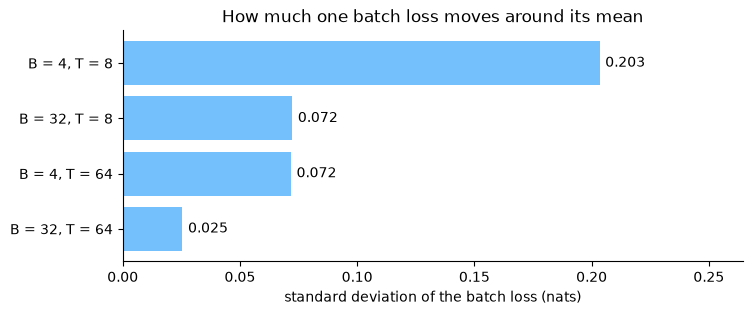

In [35]:
# What would B = 32 or T = 64 change? Spread of the section 3 table's loss over 2,000 batches.
position_loss = -torch.log(train_probs[train_data[:-1], train_data[1:]])  # predict i + 1 from i
SHAPES = [(4, 8), (32, 8), (4, 64), (32, 64)]

spreads = {}
for B, T in SHAPES:
    starts = torch.randint(len(train_data) - T, (2000, B))  # the same rule as get_batch
    windows = starts[:, :, None] + torch.arange(T)
    batch_losses = position_loss[windows].mean(dim=(1, 2))
    spreads[(B, T)] = batch_losses.std().item()
    print(f'B = {B}, T = {T}: {B * T} predictions, mean {batch_losses.mean():.2f}, '
          f'std {spreads[(B, T)]:.3f}')

labels = [f'B = {B}, T = {T}' for B, T in SHAPES][::-1]
values = [spreads[shape] for shape in SHAPES][::-1]
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(labels, values, color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=4)
ax.set_xlim(0, max(values) * 1.3)
ax.set_xlabel('standard deviation of the batch loss (nats)')
ax.set_title('How much one batch loss moves around its mean')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Every shape gives the same mean, 2.45, the train loss of the section 3 table, so a batch loss is a fair estimate. What changes is its noise. With B = 4 and T = 8, one batch loss moves by about 0.203 around the mean. What would B = 32 change? Batches of shape (32, 8), 256 predictions instead of 32, and a spread of 0.072, about 2.8 times smaller, since 8 times more predictions divide the noise by √8. Gradients become steadier, for 8 times more memory per batch.

What would T = 64 change? Batches of shape (4, 64), also 256 predictions, and the same 0.072 for my bigram, since it scores each position on its own. The contexts would also reach 64 characters, longer than any line of the text (63, section 1). My table ignores that, but the attention of TP2 can use it.

This matters directly for section 7. One `loss.item()` at (4, 8) can be off by about 0.2, more than the gap of 0.03 between train and validation in section 3. So I will compare losses averaged over many batches.

B = 4, T = 8, 100 steps: 3,200 predictions, about 0.32% of train positions seen
B = 4, T = 8, 1,000 steps: 32,000 predictions, about 3.14% of train positions seen
B = 32, T = 8, 100 steps: 25,600 predictions, about 2.52% of train positions seen
B = 32, T = 8, 1,000 steps: 256,000 predictions, about 22.51% of train positions seen


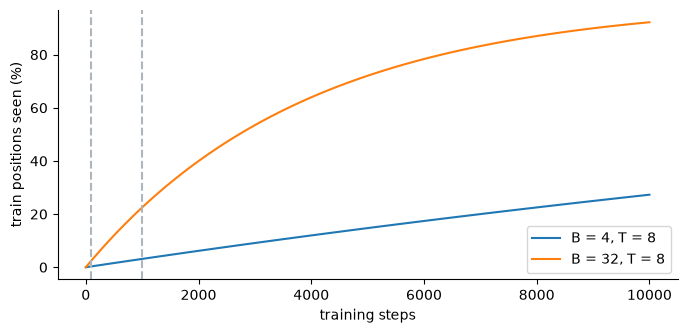

In [36]:
# How much of train do the steps of section 7 see? Each step draws B * T positions at random,
# so a position stays unseen after k steps with probability about exp(-k * B * T / n).
steps = torch.arange(0, 10_001, 100)

fig, ax = plt.subplots(figsize=(8, 3.5))
for B, T in ((4, 8), (32, 8)):
    ax.plot(steps, 100 * (1 - torch.exp(-steps * B * T / n)), label=f'B = {B}, T = {T}')
    for k in (100, 1_000):
        share = 100 * (1 - math.exp(-k * B * T / n))
        print(f'B = {B}, T = {T}, {k:,} steps: {k * B * T:,} predictions, '
              f'about {share:.2f}% of train positions seen')
for k in (100, 1_000):
    ax.axvline(k, color='#adb5bd', linestyle='--')  # 100 and 1,000 steps
ax.set_xlabel('training steps')
ax.set_ylabel('train positions seen (%)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

With B = 4 and T = 8, 100 steps see 3,200 predictions, about 0.32% of the train positions, and 1,000 steps see 32,000, about 3.14%. That is about 23 predictions for each of the 1,403 pairs that occur (section 1), enough for frequent pairs like `t` followed by a space but not for rare ones. With B = 32, 1,000 steps would see 22.51% of train. This supports my hypothesis that 100 steps barely move the loss, and suggests that 1,000 steps at B = 4 may still leave the table far from the 2.45 floor.

> *My conclusion:*
>
> `get_batch` draws B random windows of T characters from one split and returns inputs and targets shifted by one, on the GPU. With B = 4 and T = 8, a batch holds 32 independent predictions, but its loss is noisy and 1,000 steps only see about 3% of train. In section 7 I will average the loss over many batches, and I expect slow progress at this batch size. Section 5 sends `xb` into the table.
>
> My answers to the three questions of this step:
>
> 1. y needs `block_size + 1` characters after the start, so starts must stay below `len(source) - block_size`, otherwise the last rows are shorter and `torch.stack` fails.
> 2. B = 32 gives (32, 8) batches with 256 predictions, a batch loss about 2.8 times less noisy (0.072 against 0.203), and 8 times more memory.
> 3. T = 64 gives (4, 64) batches with the same 256 predictions, and contexts longer than any line, which my bigram ignores but attention can use.

## 5. Produce logits with a table

My first model is only a table. Each character picks one row of logits, the raw scores that softmax later turns into probabilities, one for each of the C possible next characters. I check the shapes, then how far the first loss is from my hypothesis. The diagram shows the path from ids to the loss and what I check.

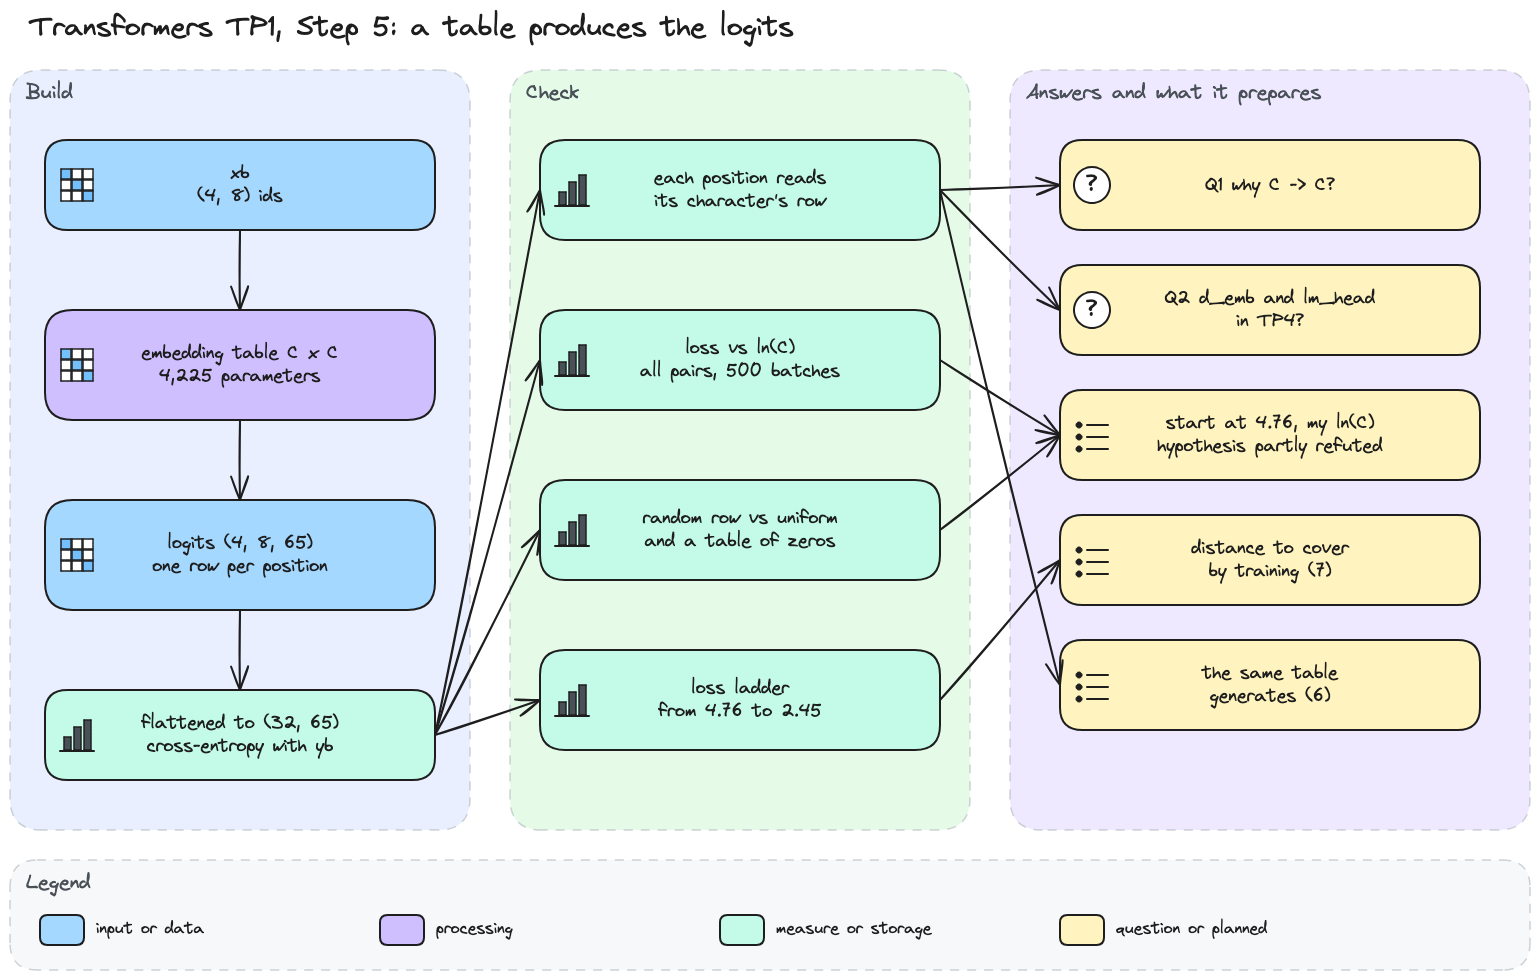

In [37]:
# Step 5 diagram: ids, table, logits and loss, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step5.png', width=900))

In [38]:
# The bigram model: an embedding table of C x C whose rows are directly the logits.
import torch.nn as nn
import torch.nn.functional as F


class BigramLanguageModel(nn.Module):
    """Bigram model: each character picks one row of scores for the next character."""

    def __init__(self, vocab_size: int):
        super().__init__()
        self.token_embedding_table = nn.Embedding(
            vocab_size, vocab_size
        )

    def forward(self, idx: torch.Tensor, targets: torch.Tensor | None = None):
        """Logits for the ids idx, and the cross-entropy loss when targets are given."""
        logits = self.token_embedding_table(idx)
        # idx: (B,T) -> logits: (B, T, C)
        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx: torch.Tensor, max_new_tokens: int) -> torch.Tensor:
        """Extend idx by max_new_tokens ids, each drawn from the scores of the last position."""
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(
                probs, num_samples=1
            )
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [39]:
# Build the table from a fresh seed, then run one batch without and with targets.
torch.manual_seed(RANDOM_STATE)  # the starting table only depends on the seed
model = BigramLanguageModel(vocab_size).to(device)

logits, _ = model(xb)
flat_logits, loss = model(xb, yb)
table = model.token_embedding_table.weight

print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
print(f'xb {tuple(xb.shape)} -> logits {tuple(logits.shape)}')
print(f'With targets: logits {tuple(flat_logits.shape)}, targets {tuple(yb.view(-1).shape)}')
print(f'Loss on this batch: {loss.item():.2f}')
print(f'Each position reads the row of its character: {torch.equal(logits, table[xb])}')

Parameters: 4,225
xb (4, 8) -> logits (4, 8, 65)
With targets: logits (32, 65), targets (32,)
Loss on this batch: 4.89
Each position reads the row of its character: True


The table holds 4,225 parameters, 65 rows of 65 scores. A batch of shape (4, 8) becomes logits of shape (4, 8, 65), one row of 65 scores for each of the 32 positions. With targets, the model flattens them to (32, 65) and (32,), because cross-entropy expects one row of scores and one target id per prediction. So the 4 sequences of 8 become 32 independent predictions. The check prints True, so each position simply reads the row of its own character. The same character always gives the same scores, whatever comes before it, which is exactly what a bigram is.

Why C → C then? The rows are the C possible current characters, and each row holds one score per possible next character. Nothing sits between the lookup and the scores, so the table needs C columns too. In TP4 this table will split in two. `token_embedding_table` will have `d_emb` columns, a vector that the blocks transform with the context, and `lm_head` will turn that vector back into C logits. Here the single table plays both parts.

This batch gives a loss of 4.89, above the 4.17 of my hypothesis. Section 4 showed that one batch is noisy, so I measure on all train pairs.

ln(65) = 4.17 nats
Untrained table on all train pairs: 4.76 nats
500 batch losses: mean 4.76, std 0.17, from 4.24 to 5.20


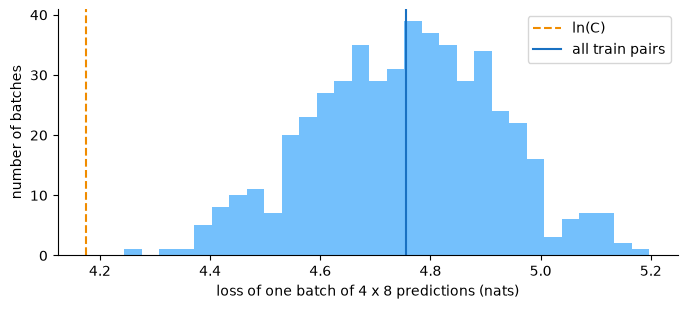

In [40]:
# Is the loss before training close to ln(C)? All train pairs at once, then 500 batch losses.
with torch.no_grad():
    weights = model.token_embedding_table.weight.cpu()
    # The loss of a bigram table only depends on how often each pair occurs (section 3).
    full_loss = (-(train_pairs * F.log_softmax(weights, dim=1)).sum()
                 / train_pairs.sum()).item()
    batch_losses = torch.tensor([model(*get_batch("train"))[1].item() for _ in range(500)])

print(f'ln({vocab_size}) = {math.log(vocab_size):.2f} nats')
print(f'Untrained table on all train pairs: {full_loss:.2f} nats')
print(f'500 batch losses: mean {batch_losses.mean():.2f}, std {batch_losses.std():.2f}, '
      f'from {batch_losses.min():.2f} to {batch_losses.max():.2f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(batch_losses, bins=30, color='#74c0fc')
ax.axvline(math.log(vocab_size), color='#f08c00', linestyle='--', label='ln(C)')
ax.axvline(full_loss, color='#1971c2', label='all train pairs')
ax.set_xlabel('loss of one batch of 4 x 8 predictions (nats)')
ax.set_ylabel('number of batches')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

On all train pairs, the untrained table gives 4.76 nats, 0.59 above ln(65). So my hypothesis is only partly right. The loss starts at the size of ln(C), but clearly above it. The 500 batches agree with a mean of 4.76, yet one batch alone ranges from 4.24 to 5.20, with a std of 0.17. A single lucky batch at 4.24 could have made me believe the hypothesis.

Why would a random table do worse than a uniform guess?

Weights: mean 0.00, std 1.00
Largest probability in a row, on average: 0.101, uniform: 0.0154
Expected loss for random scores of std 1: 4.67 nats
Table of zeros on all train pairs: 4.17 nats


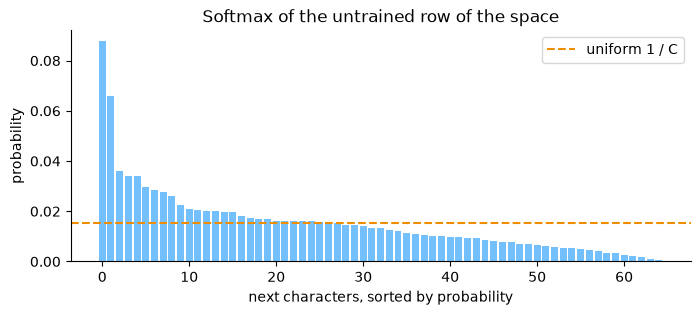

In [41]:
# Why is a random table not uniform? Softmax of the space row, sorted, against the uniform 1 / C.
probs = F.softmax(weights, dim=1)
space_row = probs[stoi[' ']].sort(descending=True).values
zero_loss = (-(train_pairs * F.log_softmax(torch.zeros_like(weights), dim=1)).sum()
             / train_pairs.sum()).item()

print(f'Weights: mean {weights.mean():.2f}, std {weights.std():.2f}')
print(f'Largest probability in a row, on average: {probs.max(dim=1).values.mean():.3f}, '
      f'uniform: {1 / vocab_size:.4f}')
# Scores of std 1: the log of the sum of their exponentials is about ln(C) + 1/2, while the
# score of the target is 0 on average, so each prediction costs about ln(C) + 0.5.
print(f'Expected loss for random scores of std 1: {math.log(vocab_size) + 0.5:.2f} nats')
print(f'Table of zeros on all train pairs: {zero_loss:.2f} nats')

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(vocab_size), space_row, color='#74c0fc')
ax.axhline(1 / vocab_size, color='#f08c00', linestyle='--', label='uniform 1 / C')
ax.set_xlabel('next characters, sorted by probability')
ax.set_ylabel('probability')
ax.set_title('Softmax of the untrained row of the space')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The weights start with a mean of 0 and a std of 1, and through softmax such scores are far from equal. In the space row, the most likely next character gets more than 0.08 while others get almost nothing. Over all rows, the largest probability averages 0.101, about 6.6 times the uniform 0.0154. The target is usually not among the favoured characters, so each prediction pays about 0.5 nats more than a uniform guess. That gives an expected 4.67, close to the 4.76 I measured. A table of zeros gives exactly 4.17. So my hypothesis would hold for a table that starts at zero, and the random start costs about half a nat.

I now place this starting point among the levels I measured in sections 1 and 3.

Distance from the start to the perfect bigram on train: 2.30 nats


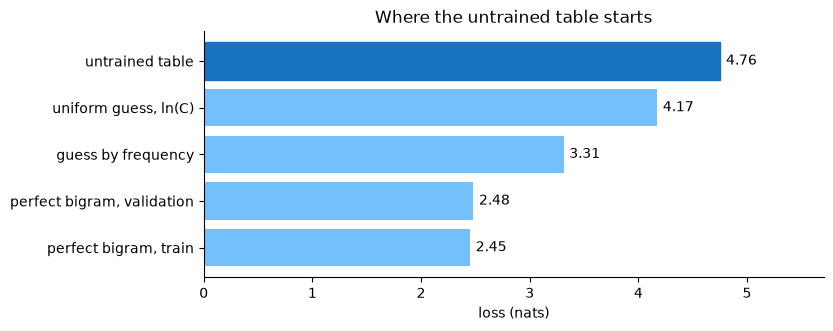

In [42]:
# Where does the untrained table start? Its loss against the levels of sections 1 and 3.
levels = {'untrained table': full_loss, 'uniform guess, ln(C)': math.log(vocab_size),
          'guess by frequency': entropy, 'perfect bigram, validation': val_loss,
          'perfect bigram, train': train_loss}
names, values = list(levels)[::-1], list(levels.values())[::-1]
print(f'Distance from the start to the perfect bigram on train: {full_loss - train_loss:.2f} nats')

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(names, values, color='#74c0fc')
bars[-1].set_color('#1971c2')  # the untrained table, on top
ax.bar_label(bars, labels=[f'{value:.2f}' for value in values], padding=4)
ax.set_xlim(0, max(values) * 1.2)
ax.set_xlabel('loss (nats)')
ax.set_title('Where the untrained table starts')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The untrained table starts above even the uniform guess. Training has 2.30 nats to cover on train, and I picture it in three stages. The table first has to lose its random preferences to reach 4.17, then learn how often each character appears to reach 3.31, then learn which character follows which to approach 2.45. On validation, 2.48 is the best a table counted on train can do. Section 7 measures how far 100 and 1,000 steps go on this ladder.

> *My conclusion:*
>
> The bigram model is one C x C table of 4,225 parameters. It turns a batch of shape (4, 8) into logits of shape (4, 8, 65) and, with targets, into 32 predictions scored by cross-entropy. Untrained, it starts at 4.76 nats, above the 4.17 of my hypothesis, because random scores of std 1 are far from uniform. Section 6 uses this same untrained table to generate text, and section 7 trains it toward 2.45.
>
> My answers to the two questions of this step:
>
> 1. The table is C by C because each of the C current characters needs one score for each of the C possible next characters, with nothing in between.
> 2. In TP4 the table splits into `token_embedding_table`, of width `d_emb`, and `lm_head`, which maps `d_emb` back to the C logits, with the blocks between them.

## 6. Generate before training

Before training, I want to see what the table writes. The `generate` method of my class reads the scores of the last position, draws the next character from their softmax, appends it and starts again. I run it now on random weights, so section 7 can repeat exactly the same procedure after training, and the diagram shows the loop and my checks.

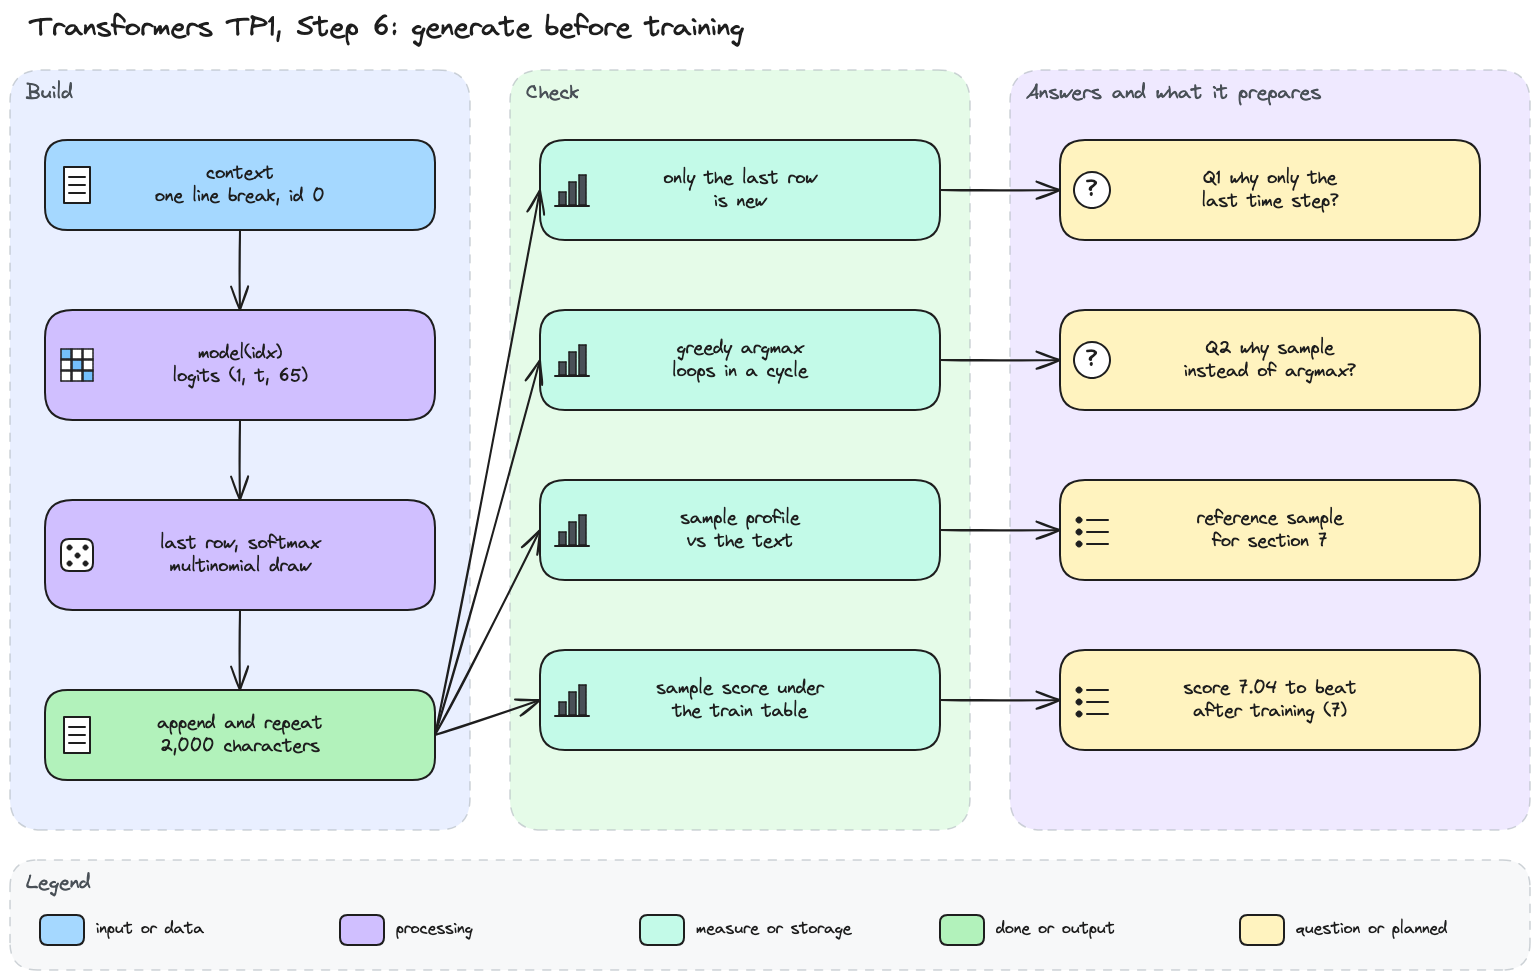

In [43]:
# Step 6 diagram: the generation loop and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step6.png', width=900))

In [44]:
# Generate 2,000 characters from a single line break with the untrained table.
torch.manual_seed(RANDOM_STATE)  # the same sample at every run
context = torch.zeros((1, 1), dtype=torch.long, device=device)  # id 0 is the line break
sample_ids = model.generate(context, max_new_tokens=2000)[0].tolist()
sample = decode(sample_ids)

print(f'Generated: {len(sample_ids) - 1:,} characters after the context')
print(sample[:300])

Generated: 2,000 characters after the context

X;wVzBZxtXtKOY?nMHH$imWClMLKLoiCEavkET'-r$ijdO'Xn'3sdtueXccQHc,qnwdJnUN
  ;
!tZi y$,gzNwH$J
S:wyci3GPM
Dp&ZnERV!,BGOMvs!,iHLi3CYwVmG$AQz&xgJpcxW-m3UXz,BnCgZ&PHLapEZx?Q..:mP?AsYDJKU.'ir:mtQHLXaxgucQDxLMDvTBX!,FA'gHuordVlI;fOMq J&iqjvaP:rM,gSVHPTWe'g.jhCY3Z-MZUp-JnYxnK3Lg..Th&JPAOEm:gHcN TJq'JPwuo,Zi


The untrained table writes noise. Capitals, lowercase letters and signs come in any order, like `X;wVzBZxtXtKOY?nMHH$im`, with very few spaces and no word at all. That is what random rows give, since each character points to followers chosen by chance. The method carries `@torch.no_grad()` because generation never calls backward, so keeping the graph of 2,000 forward passes would only cost memory.

Each step runs the model on the whole context but only uses one row of its output. I want to see why.

In [45]:
# Why keep only the last time step? The logits of a context of 8 characters, row by row.
idx = torch.tensor([encode("First Ci")], device=device)
with torch.no_grad():
    logits, _ = model(idx)

print(f'Context of {idx.shape[1]} characters -> logits {tuple(logits.shape)}')
print(f'The last row is the table row of {decode([idx[0, -1].item()])!r}: '
      f'{torch.equal(logits[:, -1, :], table[idx[:, -1]])}')
print(f'Rows 0 to 6 predict characters already in the context: {decode(idx[0, 1:].tolist())!r}')

Context of 8 characters -> logits (1, 8, 65)
The last row is the table row of 'i': True
Rows 0 to 6 predict characters already in the context: 'irst Ci'


A context of 8 characters gives logits of shape (1, 8, 65), one row per position. Row t predicts the character after position t, so rows 0 to 6 predict `irst Ci`, which is already in the context. Only the last row predicts the unknown next character. Why keep only the last time step then? Because it is the only prediction I do not have yet. For my bigram that row is exactly the table row of the last character, `i`, as the check confirms. So `generate` computes 8 rows to use one. That waste does not matter here, and it shows the method is written for models whose last row depends on the whole context, like the one of TP4.

The model then draws the next character instead of taking the most likely one. I check what the most likely one would give.

In [46]:
# Why draw with multinomial instead of taking the most likely character? Greedy from a line break.
current, greedy_ids = 0, [0]
with torch.no_grad():
    for _ in range(60):
        current = int(table[current].argmax())
        greedy_ids.append(current)
print(repr(decode(greedy_ids)))

first_seen = {}
for step, char_id in enumerate(greedy_ids):
    if char_id in first_seen:
        print(f'Cycle from step {first_seen[char_id]}, length {step - first_seen[char_id]}')
        break
    first_seen[char_id] = step

'\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhS'
Cycle from step 0, length 9


Taking the most likely character gives `\ngZ&XhSkJ` again and again, a cycle of 9 characters from the very first step. With a bigram, each character has one fixed most likely follower, so the text loops as soon as a character comes back, after at most 65 steps. Why sample instead of argmax then? Sampling draws from the whole distribution, so the same character can be followed by different characters and the text keeps varying. After training, argmax would still lock onto the most common pairs, so I keep sampling in section 7 too.

Next I measure what kind of characters the sample contains.

line break: text 3.59%, untrained sample 1.35%
space: text 15.23%, untrained sample 1.5%
punctuation: text 4.88%, untrained sample 15.19%
digit: text 0.0%, untrained sample 1.95%
uppercase letter: text 7.96%, untrained sample 40.18%
lowercase letter: text 68.35%, untrained sample 39.83%


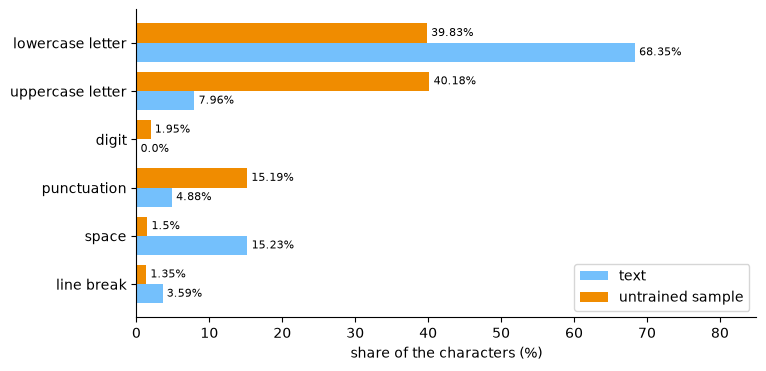

In [47]:
# What does the untrained sample look like? Character categories, sample against the whole text.
sample_occurrences = Counter(character_category(char) for char in sample)
text_shares = {cat: percentage(occurrences[cat], len(text)) for cat in CATEGORY_COLOURS}
sample_shares = {cat: percentage(sample_occurrences[cat], len(sample)) for cat in CATEGORY_COLOURS}
for cat in CATEGORY_COLOURS:
    print(f'{cat}: text {text_shares[cat]}%, untrained sample {sample_shares[cat]}%')

rows = torch.arange(len(CATEGORY_COLOURS))
fig, ax = plt.subplots(figsize=(8, 4))
for offset, shares, name, colour in ((-0.2, text_shares, 'text', '#74c0fc'),
                                     (0.2, sample_shares, 'untrained sample', '#f08c00')):
    bars = ax.barh(rows + offset, list(shares.values()), height=0.4, color=colour, label=name)
    ax.bar_label(bars, labels=[f'{share}%' for share in shares.values()], padding=3, fontsize=8)
ax.set_yticks(rows, list(CATEGORY_COLOURS))
ax.set_xlim(0, 85)
ax.set_xlabel('share of the characters (%)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The untrained sample has almost as many capitals (40.18%) as lowercase letters (39.83%), against 7.96% and 68.35% in the text. 26 of the 65 characters are capitals, about 40%, so the sample looks like a uniform draw over the vocabulary. Spaces fall from 15.23% to 1.5% and line breaks from 3.59% to 1.35%, so the untrained table knows nothing of words or lines. After training, in section 7, the same profile should move toward the text.

The profile counts characters one by one. I also want a number for the pairs the sample uses.

In [48]:
# How far is the sample from Shakespeare? Its pairs scored by the add-one table of section 3.
sample_tensor = torch.tensor(sample_ids)
sample_score = -torch.log(smoothed[sample_tensor[:-1], sample_tensor[1:]]).mean().item()
print(f'Untrained sample: {sample_score:.2f} nats per character')
print(f'Real validation text: {val_loss:.2f} nats per character')

Untrained sample: 7.04 nats per character
Real validation text: 2.48 nats per character


Scored by the table counted on train, the untrained sample costs 7.04 nats per character, against 2.48 for real validation text. The score is the average of −ln P(next | current) over the pairs of the sample, so it grows when the sample uses pairs Shakespeare rarely writes. It is even above the uniform 4.17, because two thirds of the possible pairs never occur in the text (section 1). After training, a new sample should come close to 2.48, since it should use the same pairs as the text. This is the number I compare in section 7.

> *My conclusion:*
>
> `generate` extends a context one character at a time, from the scores of the last position and a random draw. With the untrained table, it writes noise with as many capitals as lowercase letters, few spaces, and a score of 7.04 nats per character under the train table. This sample is my reference. Section 7 trains the table, then generates again with the same seed.
>
> My answers to the two questions this step raises:
>
> 1. Generation keeps only the last time step because the other rows predict characters already in the context, and only the last one predicts the next character.
> 2. Generation samples instead of taking argmax because argmax maps each character to one fixed follower, so the text falls into a loop, 9 characters long here.

## 7. Train, then compare

I will train the table with AdamW and compare the loss and the samples after 100 and 1,000 steps. I will read the loss against the levels of section 1, 3.31 nats by frequency and 2.45 for a perfect bigram table. On validation, my reference is the 2.48 that a table counted on train reaches (section 3). One batch loss is noisy (section 4), so I will average it over many batches. I will also generate again with the same seed and compare the profile and the score with section 6. This is where I test what 100 and 1,000 steps change and what a bigram model can learn.

## Summary

I will gather what I measured at each step and what it taught me about how a language model learns from raw text.